# Yolo Comparison #

Figuring out the best Yolo model for efficient (edge) vehicle tracking and detection

### Model comparison table

![YOLO models table comparison](YoloResearchData/YoloModelsTableComparison.png)

### Scaling curves (mAP, size, CPU / GPU speed)

![YOLO models graph comparison](YoloResearchData/YoloModelsGraphComparison.png)

## Decision: YOLO26 #

We are opting for **YOLO26**. It has the best accuracy at every size and the fastest CPU inference of the nano models, and it is NMS-free, which makes it well suited to edge deployment.


In [2]:
%pip install -q torch torchvision ultralytics opencv-python matplotlib

import time
from pathlib import Path

import cv2
import numpy as np
import torch
import matplotlib.pyplot as plt
from ultralytics import YOLO

Note: you may need to restart the kernel to use updated packages.


## Setup: model, classes, paths #

Pretrained YOLO26n with COCO classes, so no training is needed. People, bikes (bicycle + motorcycle) and vehicles (car, bus, truck) are tracked with ByteTrack.

In [3]:
import time
from pathlib import Path

import cv2
import torch
import matplotlib.pyplot as plt
from ultralytics import YOLO

# ---------- Paths (local) ----------
# Project root = first folder (going up from this notebook) that contains "data/".
PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data").is_dir())
VIDEO_DIR    = PROJECT_ROOT / "data" / "videos"
OUTPUT_DIR   = PROJECT_ROOT / "data" / "outputs"
MODELS_DIR   = PROJECT_ROOT / "models"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
MODELS_DIR.mkdir(parents=True, exist_ok=True)

VIDEO_PATH = VIDEO_DIR / "6_11_26_morning_cam2.mp4"

# ---------- Settings ----------
MODEL_PATH = MODELS_DIR / "yolo26n.pt"   # downloaded here (~5 MB) on first run
CONF       = 0.35                        # min detection confidence
IMGSZ      = 640                         # inference size; lower (480/416) = faster on CPU
TRACKER    = "bytetrack.yaml"            # lighter than the default botsort on CPU
DEVICE     = 0 if torch.cuda.is_available() else "cpu"

# COCO class id -> name
TARGET_CLASSES = {
    0: "person",
    1: "bicycle",
    2: "car",
    3: "motorcycle",
    5: "bus",
    7: "truck",
}

# ---------- Model ----------
model = YOLO(str(MODEL_PATH) if MODEL_PATH.exists() else MODEL_PATH.name)
if not MODEL_PATH.exists():                      # first run: move the downloaded weights into models/
    Path(MODEL_PATH.name).replace(MODEL_PATH)
for cid, name in TARGET_CLASSES.items():
    assert model.names[cid] == name, f"class {cid} is {model.names[cid]!r}, expected {name!r}"

# ---------- Video info ----------
assert VIDEO_PATH.exists(), f"Video not found: {VIDEO_PATH}"
cap = cv2.VideoCapture(str(VIDEO_PATH))
FPS     = cap.get(cv2.CAP_PROP_FPS) or 30
WIDTH   = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
HEIGHT  = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
NFRAMES = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
cap.release()

print(f"Project : {PROJECT_ROOT}")
print(f"Model   : {MODEL_PATH.name} on {DEVICE}")
print(f"Classes : {list(TARGET_CLASSES.values())}")
print(f"Video   : {VIDEO_PATH.name}  {WIDTH}x{HEIGHT} @ {FPS:.1f} fps, {NFRAMES} frames ({NFRAMES / FPS:.1f}s)")

Project : c:\hammad's_everything\myProjects\VehicleTollingSystem
Model   : yolo26n.pt on cpu
Classes : ['person', 'bicycle', 'car', 'motorcycle', 'bus', 'truck']
Video   : 6_11_26_morning_cam2.mp4  960x1080 @ 15.0 fps, 4515 frames (301.0s)


## Inference: track and count #

Writes an annotated video to `data/outputs/` and counts unique track IDs per class.

requirements: Ultralytics requirement ['lap>=0.5.12'] not found, attempting AutoUpdate...
   ---------------------------------------- 0.0/1.5 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.5 MB ? eta -:--:--
   ------- -------------------------------- 0.3/1.5 MB ? eta -:--:--
   --------------------- ------------------ 0.8/1.5 MB 3.2 MB/s eta 0:00:01
   ---------------------------------------- 1.5/1.5 MB 4.3 MB/s  0:00:00

requirements: AutoUpdate success  6.1s
WARNING requirements: Restart runtime or rerun command for updates to take effect

frame 0/4515  (0.1 fps)
frame 100/4515  (4.2 fps)
frame 200/4515  (6.1 fps)
frame 300/4515  (7.4 fps)
frame 400/4515  (8.2 fps)
frame 500/4515  (8.8 fps)
frame 600/4515  (9.3 fps)
frame 700/4515  (9.6 fps)
frame 800/4515  (9.9 fps)
frame 900/4515  (10.1 fps)
frame 1000/4515  (10.3 fps)
frame 1100/4515  (10.4 fps)
frame 1200/4515  (10.6 fps)
frame 1300/4515  (10.7 fps)
frame 1400/4515  (10.9 fps)
frame 1500/4515  (11.0 fps)
fram

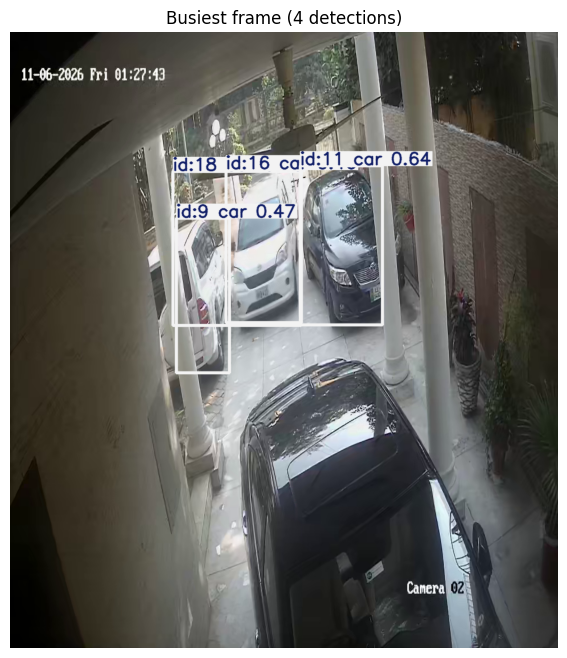

In [4]:
out_path = OUTPUT_DIR / f"{VIDEO_PATH.stem}_tracked.mp4"
writer = cv2.VideoWriter(str(out_path), cv2.VideoWriter_fourcc(*"mp4v"), FPS, (WIDTH, HEIGHT))

unique_ids = {name: set() for name in TARGET_CLASSES.values()}
sample_frame, best_count = None, 0
t0 = time.time()

results = model.track(
    source=str(VIDEO_PATH),
    classes=list(TARGET_CLASSES),
    conf=CONF,
    imgsz=IMGSZ,
    tracker=TRACKER,
    device=DEVICE,
    persist=True,
    stream=True,      # generator: one frame at a time, low memory
    verbose=False,
)

for i, r in enumerate(results):
    annotated = r.plot()
    writer.write(annotated)

    if r.boxes.id is not None:
        for cls, tid in zip(r.boxes.cls.int().tolist(), r.boxes.id.int().tolist()):
            unique_ids[TARGET_CLASSES[cls]].add(tid)
        if len(r.boxes) > best_count:          # keep the busiest frame to preview
            best_count, sample_frame = len(r.boxes), annotated.copy()

    if i % 100 == 0:
        print(f"frame {i}/{NFRAMES}  ({(i + 1) / (time.time() - t0):.1f} fps)")

writer.release()
elapsed = time.time() - t0

print()
print(f"Done: {i + 1} frames in {elapsed:.1f}s ({(i + 1) / elapsed:.1f} fps)")
print(f"Saved: {out_path}")
print()
print("Unique objects tracked:")
for name, ids in unique_ids.items():
    print(f"  {name:<11}{len(ids)}")

if sample_frame is not None:
    plt.figure(figsize=(14, 8))
    plt.imshow(cv2.cvtColor(sample_frame, cv2.COLOR_BGR2RGB))
    plt.title(f"Busiest frame ({best_count} detections)")
    plt.axis("off")
    plt.show()

## Comparing bigger YOLO26 models: s, m, l, x #

Same video, classes and tracker settings as above; only the model changes. Weights are stored in `models/`, and each run saves `data/outputs/<video>_<model>_tracked.mp4`.

Run the setup cell above first.

In [5]:
# ---------- Compare settings ----------
VARIANTS    = ["yolo26s", "yolo26m", "yolo26l", "yolo26x"]
MAX_SECONDS = None   # e.g. 60 to test only the first minute of video; None = full video


def load_model(name):
    """Load weights from models/, downloading them there on first use."""
    path = MODELS_DIR / f"{name}.pt"
    if not path.exists():
        YOLO(f"{name}.pt")                 # ultralytics downloads into the current folder
        Path(f"{name}.pt").replace(path)   # move it into models/
    return YOLO(str(path))


def run_tracking(model, tag):
    """Track TARGET_CLASSES on VIDEO_PATH, save an annotated video, return stats."""
    out_path = OUTPUT_DIR / f"{VIDEO_PATH.stem}_{tag}_tracked.mp4"
    writer = cv2.VideoWriter(str(out_path), cv2.VideoWriter_fourcc(*"mp4v"), FPS, (WIDTH, HEIGHT))
    max_frames = int(MAX_SECONDS * FPS) if MAX_SECONDS else NFRAMES

    unique_ids = {name: set() for name in TARGET_CLASSES.values()}
    sample_frame, best_count, n = None, 0, 0
    t0 = time.time()

    results = model.track(
        source=str(VIDEO_PATH),
        classes=list(TARGET_CLASSES),
        conf=CONF,
        imgsz=IMGSZ,
        tracker=TRACKER,
        device=DEVICE,
        persist=True,
        stream=True,
        verbose=False,
    )
    for i, r in enumerate(results):
        if i >= max_frames:
            break
        annotated = r.plot()
        writer.write(annotated)
        n = i + 1

        if r.boxes.id is not None:
            for cls, tid in zip(r.boxes.cls.int().tolist(), r.boxes.id.int().tolist()):
                unique_ids[TARGET_CLASSES[cls]].add(tid)
            if len(r.boxes) > best_count:
                best_count, sample_frame = len(r.boxes), annotated.copy()

        if i % 200 == 0:
            print(f"  [{tag}] frame {i}/{max_frames}  ({n / (time.time() - t0):.1f} fps)")

    writer.release()
    elapsed = time.time() - t0
    print(f"  [{tag}] done: {n} frames in {elapsed:.0f}s ({n / elapsed:.1f} fps) -> {out_path.name}")

    return {
        "model": tag,
        "frames": n,
        "seconds": elapsed,
        "fps": n / elapsed,
        "counts": {k: len(v) for k, v in unique_ids.items()},
        "video": out_path,
        "sample": sample_frame,
        "best_count": best_count,
    }


# Download any missing weights up front
for name in VARIANTS:
    load_model(name)
print("Weights in models/:", sorted(p.name for p in MODELS_DIR.glob("*.pt")))

Weights in models/: ['yolo26l.pt', 'yolo26m.pt', 'yolo26n.pt', 'yolo26s.pt', 'yolo26x.pt']


*reviewing the video footage shows that the smallest n variant is unable to track cars that are not fully present in the camera or obstructed, and detection is jittery*


*trying all variants to find the sweet spot*

### Run all variants #

In [6]:
# Runs every variant in VARIANTS. On a CPU this is slow: yolo26n took ~10 min on this video,
# and x is roughly 10x heavier, so expect hours for the full set. Set MAX_SECONDS above for a quick test.
compare_results = []
for name in VARIANTS:
    print(f"\n=== {name} ===")
    compare_results.append(run_tracking(load_model(name), name))


=== yolo26s ===
  [yolo26s] frame 0/4515  (3.0 fps)
  [yolo26s] frame 200/4515  (6.9 fps)
  [yolo26s] frame 400/4515  (7.0 fps)
  [yolo26s] frame 600/4515  (7.1 fps)
  [yolo26s] frame 800/4515  (7.1 fps)
  [yolo26s] frame 1000/4515  (7.1 fps)
  [yolo26s] frame 1200/4515  (7.1 fps)
  [yolo26s] frame 1400/4515  (7.2 fps)
  [yolo26s] frame 1600/4515  (7.2 fps)
  [yolo26s] frame 1800/4515  (7.2 fps)
  [yolo26s] frame 2000/4515  (7.1 fps)
  [yolo26s] frame 2200/4515  (7.1 fps)
  [yolo26s] frame 2400/4515  (7.1 fps)
  [yolo26s] frame 2600/4515  (7.1 fps)
  [yolo26s] frame 2800/4515  (7.1 fps)
  [yolo26s] frame 3000/4515  (7.1 fps)
  [yolo26s] frame 3200/4515  (7.1 fps)
  [yolo26s] frame 3400/4515  (7.1 fps)
  [yolo26s] frame 3600/4515  (7.1 fps)
  [yolo26s] frame 3800/4515  (7.1 fps)
  [yolo26s] frame 4000/4515  (7.1 fps)
  [yolo26s] frame 4200/4515  (7.1 fps)
  [yolo26s] frame 4400/4515  (7.1 fps)
  [yolo26s] done: 4515 frames in 633s (7.1 fps) -> 6_11_26_morning_cam2_yolo26s_tracked.mp4



### Results #

model         fps  time (s)      person     bicycle         car  motorcycle         bus       truck
---------------------------------------------------------------------------------------------------
yolo26s       7.1       633           6           0          13           0          57           0
yolo26m       2.9      1578           8           0          10           0           2           2
yolo26l       2.3      1963           6           0          15           0           0           1
yolo26x       1.2      3883           7           0          15           0           0           1

Videos saved:
  c:\hammad's_everything\myProjects\VehicleTollingSystem\data\outputs\6_11_26_morning_cam2_yolo26s_tracked.mp4
  c:\hammad's_everything\myProjects\VehicleTollingSystem\data\outputs\6_11_26_morning_cam2_yolo26m_tracked.mp4
  c:\hammad's_everything\myProjects\VehicleTollingSystem\data\outputs\6_11_26_morning_cam2_yolo26l_tracked.mp4
  c:\hammad's_everything\myProjects\VehicleTollingSy

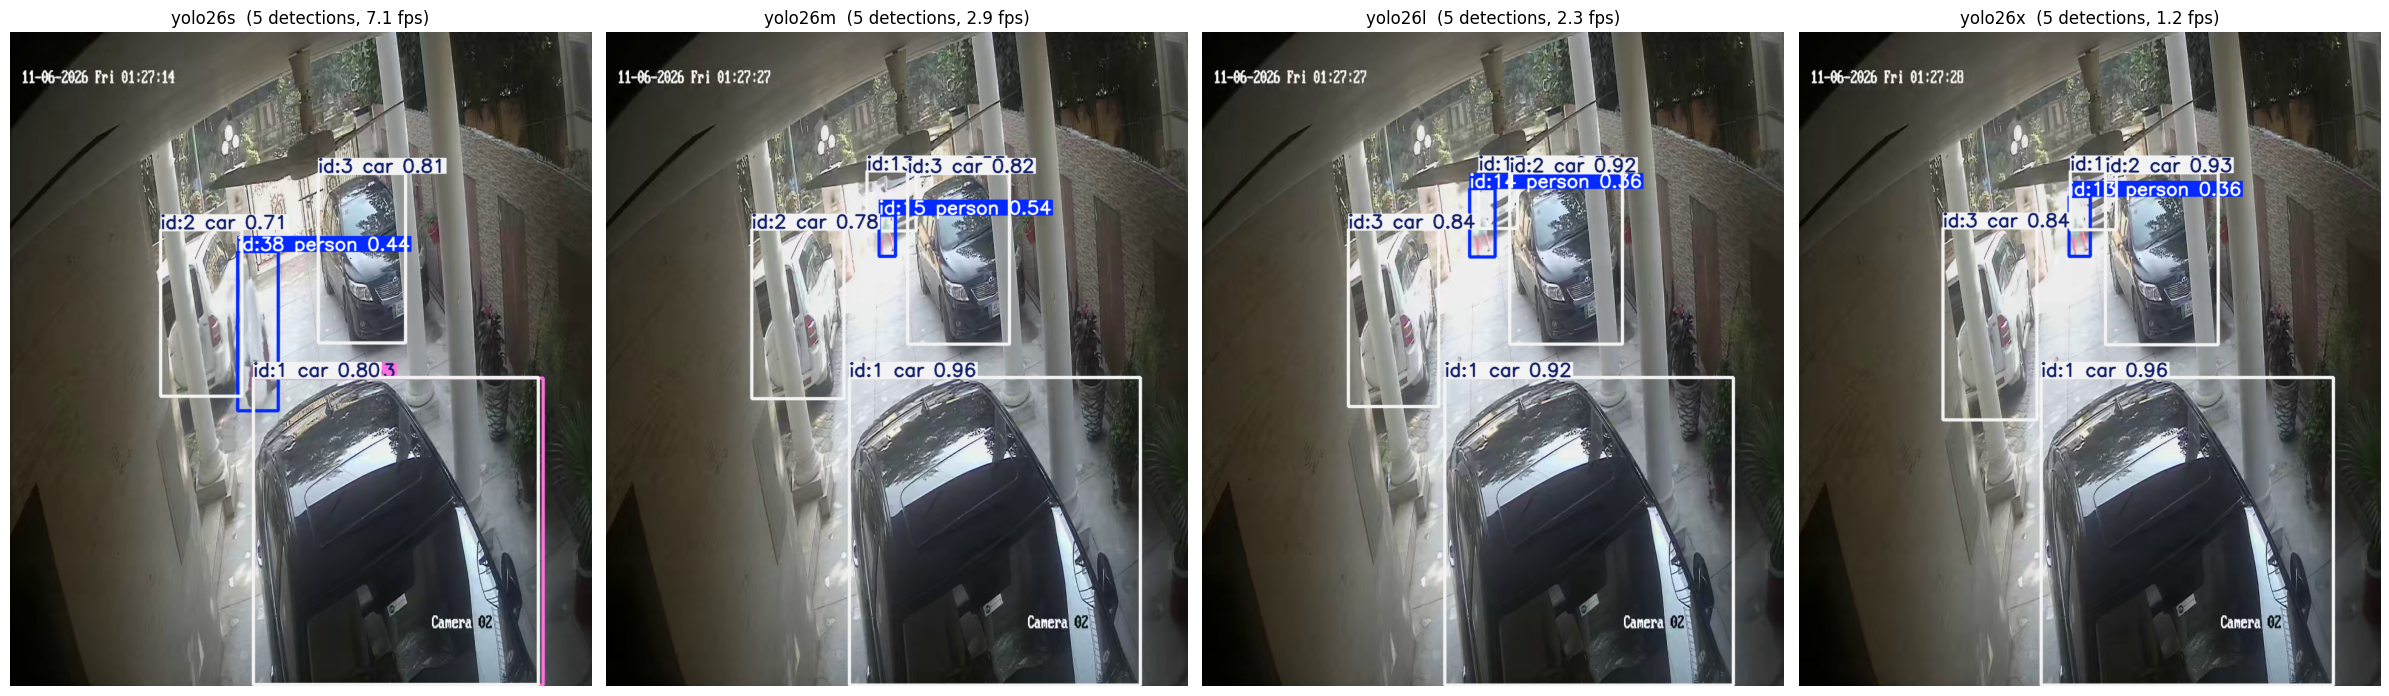

In [7]:
# ---------- Summary table ----------
classes = list(TARGET_CLASSES.values())
header = f"{'model':<10}{'fps':>7}{'time (s)':>10}" + "".join(f"{c:>12}" for c in classes)
print(header)
print("-" * len(header))
for res in compare_results:
    print(f"{res['model']:<10}{res['fps']:>7.1f}{res['seconds']:>10.0f}"
          + "".join(f"{res['counts'][c]:>12}" for c in classes))

print("\nVideos saved:")
for res in compare_results:
    print(" ", res["video"])

# ---------- Busiest frame from each model ----------
fig, axes = plt.subplots(1, len(compare_results), figsize=(6 * len(compare_results), 7))
axes = [axes] if len(compare_results) == 1 else axes
for ax, res in zip(axes, compare_results):
    if res["sample"] is not None:
        ax.imshow(cv2.cvtColor(res["sample"], cv2.COLOR_BGR2RGB))
    ax.set_title(f"{res['model']}  ({res['best_count']} detections, {res['fps']:.1f} fps)")
    ax.axis("off")
plt.tight_layout()
plt.show()

*Even the S variant is running perfectly, and also has low inference speed (even if double that of n)*

## Camera calibration #

Each camera gets a config in `cameraConfigs/<camera_id>.json` with:

- **camera_type**: `passageway` (cars cross the frame and leave) or `parking_zone` (cars drive in and park in view)
- **entry** / **exit** arrows: the direction an entering / exiting car moves, in pixels and normalised 0-1 coords
- **gate_zone**: a polygon every entering/exiting car drives through. Cars that never touch it (e.g. main-road traffic) are ignored

For **cam1** (looking outside the gate): right → left = entering, left → right = exiting.

Running the next cell opens a separate window. Follow the prompts in it.

In [10]:
# Opens an OpenCV window (outside VS Code) on the camera video. Steps:
#   1. choose camera type: passageway or parking zone
#   2. drag the ENTRY arrow   3. drag the EXIT arrow
#   4. click the corners of the GATE ZONE (only cars that pass through it count)
#   5. save
# Saved to cameraConfigs/<CAMERA_ID>.json (+ a PNG snapshot of the arrows and gate zone).
import json
from datetime import datetime
from pathlib import Path

import cv2
import numpy as np

# ---------- Settings ----------
CAMERA_ID    = "cam1"
PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data").is_dir())
CALIB_VIDEO  = PROJECT_ROOT / "data" / "videos" / "6_11_26_morning_cam1.mp4"
CONFIG_DIR   = PROJECT_ROOT / "cameraConfigs"
CONFIG_PATH  = CONFIG_DIR / f"{CAMERA_ID}.json"
MAX_DISPLAY  = (1280, 720)          # window is scaled down to fit; coords are saved in full-res pixels

ENTRY_COLOR = (80, 200, 80)         # BGR green
EXIT_COLOR  = (60, 60, 230)         # BGR red
GATE_COLOR  = (0, 215, 255)         # BGR yellow
CAMERA_TYPES = {"passageway": "Passageway", "parking_zone": "Parking zone"}

CONFIG_DIR.mkdir(parents=True, exist_ok=True)
assert CALIB_VIDEO.exists(), f"Video not found: {CALIB_VIDEO}"

cap = cv2.VideoCapture(str(CALIB_VIDEO))
VID_FPS = cap.get(cv2.CAP_PROP_FPS) or 30
ok, frame = cap.read()
assert ok, "Could not read a frame from the video"
frame_idx = 0
H, W = frame.shape[:2]
scale = min(MAX_DISPLAY[0] / W, MAX_DISPLAY[1] / H, 1.0)
WIN = f"Calibrate {CAMERA_ID}"

state = {
    "stage": "type",                 # type -> entry -> exit -> gate -> review
    "cam_type": None,
    "arrows": {"entry": None, "exit": None},
    "gate": [],                      # polygon corners, full-res pixels
    "drag_start": None,
    "drag_now": None,
    "mouse": None,
    "buttons": {},
}


# ---------- Drawing helpers ----------
def to_orig(x, y):
    """Display coords -> full-resolution frame coords (clamped to the frame)."""
    return (min(max(int(round(x / scale)), 0), W - 1),
            min(max(int(round(y / scale)), 0), H - 1))


def text_box(img, lines, org=(12, 12)):
    font, fs, th, pad, lh = cv2.FONT_HERSHEY_SIMPLEX, 0.6, 1, 10, 26
    w = max(cv2.getTextSize(l, font, fs, th)[0][0] for l in lines) + 2 * pad
    h = lh * len(lines) + pad
    x, y = org
    overlay = img.copy()
    cv2.rectangle(overlay, (x, y), (x + w, y + h), (20, 20, 20), -1)
    cv2.addWeighted(overlay, 0.78, img, 0.22, 0, img)
    for i, line in enumerate(lines):
        weight = 2 if i == 0 else 1
        cv2.putText(img, line, (x + pad, y + pad + 16 + lh * i), font, fs, (255, 255, 255), weight, cv2.LINE_AA)


def button(img, key, rect, label, color):
    x1, y1, x2, y2 = rect
    cv2.rectangle(img, (x1, y1), (x2, y2), color, -1)
    cv2.rectangle(img, (x1, y1), (x2, y2), (255, 255, 255), 2)
    (tw, th), _ = cv2.getTextSize(label, cv2.FONT_HERSHEY_SIMPLEX, 0.7, 2)
    cv2.putText(img, label, (x1 + (x2 - x1 - tw) // 2, y1 + (y2 - y1 + th) // 2),
                cv2.FONT_HERSHEY_SIMPLEX, 0.7, (255, 255, 255), 2, cv2.LINE_AA)
    state["buttons"][key] = rect


def label(img, text, org, color):
    cv2.putText(img, text, org, cv2.FONT_HERSHEY_SIMPLEX, 0.8, (0, 0, 0), 4, cv2.LINE_AA)
    cv2.putText(img, text, org, cv2.FONT_HERSHEY_SIMPLEX, 0.8, color, 2, cv2.LINE_AA)


def arrow(img, start, end, color, text, s=1.0, thickness=4):
    p1 = (int(start[0] * s), int(start[1] * s))
    p2 = (int(end[0] * s), int(end[1] * s))
    length = max(np.hypot(p2[0] - p1[0], p2[1] - p1[1]), 1)
    cv2.arrowedLine(img, p1, p2, color, thickness, cv2.LINE_AA, tipLength=min(30 / length, 0.4))
    if text:
        label(img, text, (p1[0] + 8, p1[1] - 10), color)


def gate_poly(img, pts, s=1.0, closed=True, cursor=None, thickness=2):
    if not pts:
        return
    p = np.array([[int(x * s), int(y * s)] for x, y in pts], np.int32)
    if closed and len(p) >= 3:
        overlay = img.copy()
        cv2.fillPoly(overlay, [p], GATE_COLOR)
        cv2.addWeighted(overlay, 0.3, img, 0.7, 0, img)
        cv2.polylines(img, [p], True, GATE_COLOR, thickness, cv2.LINE_AA)
        label(img, "GATE", tuple(p.mean(axis=0).astype(int) - [30, 0]), GATE_COLOR)
    else:
        cv2.polylines(img, [p], False, GATE_COLOR, thickness, cv2.LINE_AA)
        if cursor is not None:                                   # rubber band to the mouse
            c = (int(cursor[0] * s), int(cursor[1] * s))
            cv2.line(img, tuple(p[-1]), c, GATE_COLOR, 1, cv2.LINE_AA)
            if len(p) >= 2:
                cv2.line(img, c, tuple(p[0]), GATE_COLOR, 1, cv2.LINE_AA)
    for q in p:
        cv2.circle(img, tuple(q), 5, GATE_COLOR, -1, cv2.LINE_AA)


def render():
    img = cv2.resize(frame, (int(W * scale), int(H * scale)))
    dh, dw = img.shape[:2]
    state["buttons"] = {}
    stage, ctype = state["stage"], CAMERA_TYPES.get(state["cam_type"], "")

    gate_poly(img, state["gate"], s=scale, closed=(stage == "review"),
              cursor=state["mouse"] if stage == "gate" else None)
    for name, color in (("entry", ENTRY_COLOR), ("exit", EXIT_COLOR)):
        if state["arrows"][name]:
            arrow(img, *state["arrows"][name], color, name.upper(), s=scale)
    if state["drag_start"] and state["drag_now"]:
        color = ENTRY_COLOR if stage == "entry" else EXIT_COLOR
        arrow(img, state["drag_start"], state["drag_now"], color, None, s=scale, thickness=2)

    if stage == "type":
        text_box(img, [
            "Step 1/4: Is this camera a passageway or a parking zone?",
            "Passageway: cars cross the frame and leave (L<->R or top<->bottom).",
            "Parking zone: cars drive in, park in view, and leave later.",
            "Click a button or press P / K.   N = skip 1 s ahead   Esc = cancel",
        ])
        bw, bh, cx, y = 270, 56, dw // 2, dh - 56 - 30
        button(img, "passageway", (cx - bw - 20, y, cx - 20, y + bh), "Passageway (P)", (150, 110, 40))
        button(img, "parking_zone", (cx + 20, y, cx + bw + 20, y + bh), "Parking zone (K)", (40, 110, 150))
    elif stage == "entry":
        text_box(img, [
            f"Step 2/4: Draw the ENTRY direction   [{ctype}]",
            "Click and drag along the path an ENTERING car takes.",
            "Backspace = back   N = skip 1 s ahead   Esc = cancel",
        ])
    elif stage == "exit":
        text_box(img, [
            f"Step 3/4: Draw the EXIT direction   [{ctype}]",
            "Click and drag along the path an EXITING car takes.",
            "Backspace = redo entry   N = skip 1 s ahead   Esc = cancel",
        ])
    elif stage == "gate":
        text_box(img, [
            f"Step 4/4: Mark the GATE ZONE   [{ctype}]   ({len(state['gate'])} points)",
            "Left-click each corner of the area every entering/exiting car drives through.",
            "Right-click or Enter = finish (3+ points)   Backspace = undo point",
            "N = skip 1 s ahead   Esc = cancel",
        ])
    elif stage == "review":
        text_box(img, [
            f"Check the arrows and gate zone   [{ctype}]",
            "S or Enter = save   R = redo everything   G = redo gate zone only",
            "Esc = cancel without saving",
        ])
    return img


def finish_gate():
    if len(state["gate"]) >= 3:
        state["stage"] = "review"


def on_mouse(event, x, y, flags, param):
    stage = state["stage"]
    state["mouse"] = to_orig(x, y)
    if stage == "type" and event == cv2.EVENT_LBUTTONDOWN:
        for key, (x1, y1, x2, y2) in state["buttons"].items():
            if x1 <= x <= x2 and y1 <= y <= y2:
                state["cam_type"], state["stage"] = key, "entry"
    elif stage in ("entry", "exit"):
        if event == cv2.EVENT_LBUTTONDOWN:
            state["drag_start"] = state["drag_now"] = to_orig(x, y)
        elif event == cv2.EVENT_MOUSEMOVE and state["drag_start"]:
            state["drag_now"] = to_orig(x, y)
        elif event == cv2.EVENT_LBUTTONUP and state["drag_start"]:
            start, end = state["drag_start"], to_orig(x, y)
            state["drag_start"] = state["drag_now"] = None
            if np.hypot(end[0] - start[0], end[1] - start[1]) < 20 / scale:
                return                                  # too short: treat as a stray click
            state["arrows"][stage] = (start, end)
            state["stage"] = "exit" if stage == "entry" else "gate"
    elif stage == "gate":
        if event == cv2.EVENT_LBUTTONDOWN:
            state["gate"].append(to_orig(x, y))
        elif event == cv2.EVENT_RBUTTONDOWN:
            finish_gate()


def arrow_dict(a):
    (x1, y1), (x2, y2) = a
    dx, dy = x2 - x1, y2 - y1
    n = float(np.hypot(dx, dy))
    return {
        "start": [x1, y1],
        "end": [x2, y2],
        "start_norm": [round(x1 / W, 4), round(y1 / H, 4)],   # 0-1, resolution independent
        "end_norm": [round(x2 / W, 4), round(y2 / H, 4)],
        "unit_vector": [round(dx / n, 4), round(dy / n, 4)],
    }


# ---------- Window loop ----------
saved = False
cv2.namedWindow(WIN, cv2.WINDOW_AUTOSIZE)
cv2.setMouseCallback(WIN, on_mouse)
try:
    while True:
        cv2.imshow(WIN, render())
        key = cv2.waitKey(20) & 0xFF
        if cv2.getWindowProperty(WIN, cv2.WND_PROP_VISIBLE) < 1 or key == 27:   # window closed / Esc
            break
        stage = state["stage"]

        if key in (ord("n"), ord("N")) and stage != "review" and not state["drag_start"]:
            for _ in range(int(VID_FPS)):
                ok, f = cap.read()
                if not ok:
                    break
                frame, frame_idx = f, frame_idx + 1

        if stage == "type":
            if key in (ord("p"), ord("P")):
                state["cam_type"], state["stage"] = "passageway", "entry"
            elif key in (ord("k"), ord("K")):
                state["cam_type"], state["stage"] = "parking_zone", "entry"
        elif stage in ("entry", "exit") and key == 8:                            # Backspace
            if stage == "exit":
                state["arrows"]["entry"], state["stage"] = None, "entry"
            else:
                state["cam_type"], state["stage"] = None, "type"
        elif stage == "gate":
            if key == 8:                                                         # Backspace
                if state["gate"]:
                    state["gate"].pop()
                else:
                    state["arrows"]["exit"], state["stage"] = None, "exit"
            elif key == 13:                                                      # Enter
                finish_gate()
        elif stage == "review":
            if key in (ord("r"), ord("R")):
                state["arrows"] = {"entry": None, "exit": None}
                state["gate"] = []
                state["stage"] = "entry"
            elif key in (ord("g"), ord("G")):
                state["gate"], state["stage"] = [], "gate"
            elif key in (ord("s"), ord("S"), 13):                               # S / Enter
                config = {
                    "camera_id": CAMERA_ID,
                    "camera_type": state["cam_type"],
                    "source": CALIB_VIDEO.relative_to(PROJECT_ROOT).as_posix(),
                    "frame_size": [W, H],
                    "calibration_frame": frame_idx,
                    "entry": arrow_dict(state["arrows"]["entry"]),
                    "exit": arrow_dict(state["arrows"]["exit"]),
                    "gate_zone": {
                        "points": [list(p) for p in state["gate"]],
                        "points_norm": [[round(x / W, 4), round(y / H, 4)] for x, y in state["gate"]],
                    },
                    "created_at": datetime.now().isoformat(timespec="seconds"),
                }
                CONFIG_PATH.write_text(json.dumps(config, indent=2))

                snap = frame.copy()
                gate_poly(snap, state["gate"], thickness=3)
                arrow(snap, *state["arrows"]["entry"], ENTRY_COLOR, "ENTRY", thickness=6)
                arrow(snap, *state["arrows"]["exit"], EXIT_COLOR, "EXIT", thickness=6)
                cv2.imwrite(str(CONFIG_DIR / f"{CAMERA_ID}_calibration.png"), snap)
                saved = True
                break
finally:
    cap.release()
    cv2.destroyWindow(WIN)
    cv2.waitKey(1)

if saved:
    e, x = config["entry"]["unit_vector"], config["exit"]["unit_vector"]
    print(f"Saved {CONFIG_PATH}")
    print(json.dumps(config, indent=2))
    if config["camera_type"] == "passageway" and (e[0] * x[0] + e[1] * x[1]) > -0.5:
        print("\nNote: for a passageway the entry and exit arrows usually point in roughly opposite directions.")
else:
    print("Calibration cancelled, nothing saved.")

Saved c:\hammad's_everything\myProjects\VehicleTollingSystem\cameraConfigs\cam1.json
{
  "camera_id": "cam1",
  "camera_type": "passageway",
  "source": "data/videos/6_11_26_morning_cam1.mp4",
  "frame_size": [
    960,
    1080
  ],
  "calibration_frame": 0,
  "entry": {
    "start": [
      732,
      416
    ],
    "end": [
      444,
      816
    ],
    "start_norm": [
      0.7625,
      0.3852
    ],
    "end_norm": [
      0.4625,
      0.7556
    ],
    "unit_vector": [
      -0.5843,
      0.8115
    ]
  },
  "exit": {
    "start": [
      364,
      740
    ],
    "end": [
      678,
      362
    ],
    "start_norm": [
      0.3792,
      0.6852
    ],
    "end_norm": [
      0.7063,
      0.3352
    ],
    "unit_vector": [
      0.639,
      -0.7692
    ]
  },
  "gate_zone": {
    "points": [
      [
        10,
        886
      ],
      [
        190,
        768
      ],
      [
        405,
        1076
      ],
      [
        12,
        1078
      ],
      [
       

### Check the saved calibration #

cam1: passageway   frame 960x1080
  entry [732, 416] -> [444, 816]   direction [-0.5843, 0.8115]
  exit  [364, 740] -> [678, 362]   direction [0.639, -0.7692]
  gate  [[10, 886], [190, 768], [405, 1076], [12, 1078], [12, 968]]


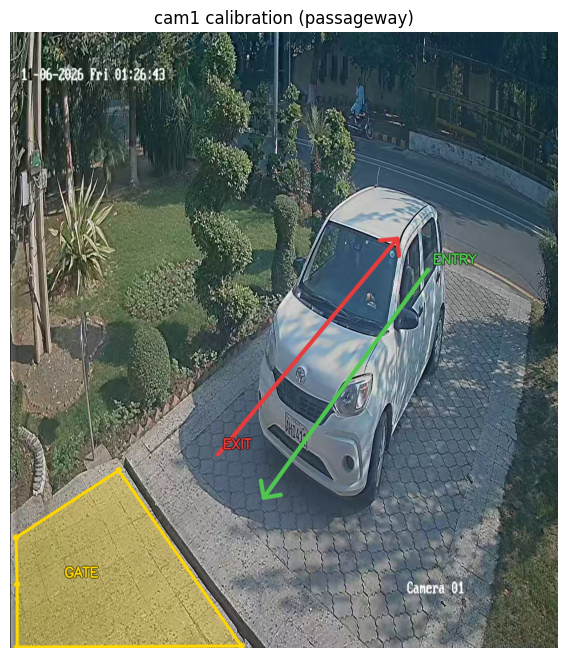

In [11]:
# Show the saved calibration for a camera
import json
import cv2
import matplotlib.pyplot as plt

cfg = json.loads(CONFIG_PATH.read_text())
print(f"{cfg['camera_id']}: {cfg['camera_type']}   frame {cfg['frame_size'][0]}x{cfg['frame_size'][1]}")
print(f"  entry {cfg['entry']['start']} -> {cfg['entry']['end']}   direction {cfg['entry']['unit_vector']}")
print(f"  exit  {cfg['exit']['start']} -> {cfg['exit']['end']}   direction {cfg['exit']['unit_vector']}")
gate = cfg.get("gate_zone")
print(f"  gate  {gate['points'] if gate else 'not set (rerun calibration)'}")

snap = cv2.imread(str(CONFIG_DIR / f"{cfg['camera_id']}_calibration.png"))
plt.figure(figsize=(14, 8))
plt.imshow(cv2.cvtColor(snap, cv2.COLOR_BGR2RGB))
plt.title(f"{cfg['camera_id']} calibration ({cfg['camera_type']})")
plt.axis("off")
plt.show()

## Entry / exit detection: cam1, YOLO26s #

Uses `cameraConfigs/cam1.json` (entry/exit arrows + gate zone). Each vehicle's point is recorded ~5x per second; once it leaves the frame its **net displacement** is compared to the entry and exit arrows (cosine similarity), so turns and three-point turns don't affect the result. Only vehicles that pass through the **gate zone** can count, which filters out main-road traffic.

Outputs in `data/outputs/`:
- `<video>_yolo26s_entry_exit.mp4`: annotated video, notifications top-right, the car's path drawn for a few seconds
- `<video>_yolo26s_events.json`: every entry/exit event (time, track, path, scores) plus ignored tracks and why

In [13]:
# Entry / exit counting for one camera, using its calibration config (arrows + gate zone).
#
# For every tracked vehicle:
#   1. record its (smoothed) box point ~5x per second, noting whether it is inside the gate zone
#   2. when the tracker has lost it for FINALIZE_AFTER_S (it left the frame), decide:
#        - never touched the gate zone            -> ignored (e.g. main-road traffic)
#        - net displacement too small             -> ignored (parked / jitter / drove in and backed out)
#        - displacement direction vs entry/exit arrows (cosine) -> best match if >= MIN_COS
#        - order check: entry = gate visited near the END of the track, exit = near the START
#   3. on entry/exit: top-right notification + the car's path drawn for NOTIFY_S seconds
# Turns and three-point turns don't matter: only where the car started and ended up counts.
import json
import time
from collections import deque
from pathlib import Path

import cv2
import numpy as np
import torch
from ultralytics import YOLO

# ---------- Settings ----------
CAMERA_ID    = "cam1"
MODEL_NAME   = "yolo26s"
PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data").is_dir())
VIDEO_PATH   = PROJECT_ROOT / "data" / "videos" / "6_11_26_morning_cam1_test_0033-0200.mp4"  # test clip; full video: 6_11_26_morning_cam1.mp4
CONFIG_PATH  = PROJECT_ROOT / "cameraConfigs" / f"{CAMERA_ID}.json"
MODELS_DIR   = PROJECT_ROOT / "models"
OUTPUT_DIR   = PROJECT_ROOT / "data" / "outputs"
TRACKER_DIR  = PROJECT_ROOT / "trackers"

IMGSZ   = 640
DEVICE  = 0 if torch.cuda.is_available() else "cpu"
VEHICLE_CLASSES = {2: "car", 3: "motorcycle", 5: "bus", 7: "truck"}

# ---------- Persistence: detector + tracker (main knobs for jittery / dropped detections) ----------
CONF              = 0.10   # detector floor. Keep LOW: weak boxes are what keep a track alive when the car blurs
TRACK_HIGH_THRESH = 0.30   # boxes above this are matched to tracks first
TRACK_LOW_THRESH  = 0.10   # weak boxes (low..high) can still CONTINUE an existing track (ByteTrack's 2nd pass)
NEW_TRACK_THRESH  = 0.40   # a NEW track only starts from a box this confident, so low CONF doesn't create junk tracks
MATCH_THRESH      = 0.85   # association leniency; higher accepts bigger jumps between frames (fast/large cars)
TRACK_BUFFER_S    = 3.0    # tracker keeps a lost ID this long, so the SAME id resumes after a dropout

# ---------- Persistence: our own track records ----------
COAST_S          = 1.0     # keep drawing a lost car (predicted box + trail) this long: no flicker on short dropouts
FINALIZE_AFTER_S = 3.0     # wait this long after the last sighting before deciding (should be >= TRACK_BUFFER_S)
EDGE_FINALIZE_S  = 0.7     # ...but decide sooner if the car was last seen touching the frame edge (it drove out)
EDGE_MARGIN_PX   = 12      # "touching the edge" = box within this many pixels of the border
STITCH_DIST_FRAC = 0.15    # new ID appearing this close (fraction of frame diagonal) to a lost car's predicted spot = same car
SMOOTH_ALPHA     = 0.4     # point smoothing between frames (1 = none, lower = smoother but laggier)
VEL_ALPHA        = 0.3     # velocity smoothing, used to predict where a lost car is

POINT_MODE       = "bottom"   # "bottom" = bottom-centre of the box (where the car meets the ground), "center" = box centre
SAMPLE_EVERY_S   = 0.2        # record the point this often
MIN_SAMPLES      = 5          # fewer recorded points than this -> ignored
MIN_DISP_FRAC    = 0.15       # net movement must be >= this fraction of the arrow length
MIN_COS          = 0.5        # direction must be within ~60 degrees of the arrow
ORDER_SPLIT      = 0.5        # entry: last gate visit in the later half of the track; exit: first gate visit in the earlier half
HIGH_CONF_COS    = 0.8        # cosine above this -> "high" confidence
NOTIFY_S         = 4.0        # how long the notification and path stay on screen
TRAIL_LEN        = 60         # recorded points shown as a live trail behind each car

ENTRY_COLOR = (80, 200, 80)   # BGR
EXIT_COLOR  = (60, 60, 230)
GATE_COLOR  = (0, 215, 255)
TRACK_COLOR = (200, 200, 200)
EVENT_COLORS = {"entry": ENTRY_COLOR, "exit": EXIT_COLOR}
EVENT_WORDS  = {"entry": "ENTERED", "exit": "EXITED"}

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
OUT_VIDEO = OUTPUT_DIR / f"{VIDEO_PATH.stem}_{MODEL_NAME}_entry_exit.mp4"
OUT_JSON  = OUTPUT_DIR / f"{VIDEO_PATH.stem}_{MODEL_NAME}_events.json"

# ---------- Video + config ----------
assert VIDEO_PATH.exists(), f"Video not found: {VIDEO_PATH}"
cfg = json.loads(CONFIG_PATH.read_text())
assert cfg.get("gate_zone"), "Config has no gate_zone: rerun the calibration cell"
assert cfg.get("config_version", 1) == 1, "This is a v2 (cropped) config: use the 'Entry / exit detection v2' cell"

cap = cv2.VideoCapture(str(VIDEO_PATH))
FPS     = cap.get(cv2.CAP_PROP_FPS) or 30
W       = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
H       = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
NFRAMES = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
cap.release()


def denorm(p):
    """Normalised config coords -> pixels of THIS video (works if the resolution differs from calibration)."""
    return np.array([p[0] * W, p[1] * H], dtype=float)


GATE = np.array([denorm(p) for p in cfg["gate_zone"]["points_norm"]], dtype=np.float32)
ARROWS = {}
for kind in ("entry", "exit"):
    s, e = denorm(cfg[kind]["start_norm"]), denorm(cfg[kind]["end_norm"])
    ARROWS[kind] = {"start": s, "end": e, "unit": (e - s) / np.linalg.norm(e - s)}

ARROW_LEN      = float(np.mean([np.linalg.norm(a["end"] - a["start"]) for a in ARROWS.values()]))
MIN_DISP       = MIN_DISP_FRAC * ARROW_LEN
STITCH_DIST    = STITCH_DIST_FRAC * float(np.hypot(W, H))
SAMPLE_EVERY   = max(1, round(SAMPLE_EVERY_S * FPS))
FINALIZE_AFTER = max(1, round(FINALIZE_AFTER_S * FPS))
EDGE_FINALIZE  = max(1, round(EDGE_FINALIZE_S * FPS))
COAST_FRAMES   = round(COAST_S * FPS)
NOTIFY_FRAMES  = round(NOTIFY_S * FPS)

# Tracker config generated from the settings above (track_buffer is in frames)
TRACKER_DIR.mkdir(parents=True, exist_ok=True)
TRACKER = TRACKER_DIR / f"{CAMERA_ID}_bytetrack.yaml"
TRACKER.write_text(
    "tracker_type: bytetrack\n"
    f"track_high_thresh: {TRACK_HIGH_THRESH}\n"
    f"track_low_thresh: {TRACK_LOW_THRESH}\n"
    f"new_track_thresh: {NEW_TRACK_THRESH}\n"
    f"track_buffer: {max(1, round(TRACK_BUFFER_S * FPS))}\n"
    f"match_thresh: {MATCH_THRESH}\n"
    "fuse_score: True\n"
)


def in_gate(pt):
    return cv2.pointPolygonTest(GATE, (float(pt[0]), float(pt[1])), False) >= 0


def fmt_time(seconds):
    m, s = divmod(seconds, 60)
    return f"{int(m):02d}:{s:04.1f}"


# ---------- Model ----------
weights = MODELS_DIR / f"{MODEL_NAME}.pt"
if not weights.exists():
    MODELS_DIR.mkdir(parents=True, exist_ok=True)
    YOLO(f"{MODEL_NAME}.pt")
    Path(f"{MODEL_NAME}.pt").replace(weights)
model = YOLO(str(weights))


# ---------- Track records ----------
class Track:
    def __init__(self, key, frame):
        self.key = key                 # display id = first tracker id
        self.ids = [key]               # all tracker ids stitched into this car
        self.first_frame = frame
        self.last_frame = frame
        self.smooth = None
        self.vel = np.zeros(2)         # smoothed px/frame, used to predict a lost car's position
        self.last_box = None
        self.samples = []              # (frame, x, y, in_gate)
        self.cls_votes = {}

    def update(self, pt, cls, frame, box):
        if self.smooth is None:
            self.smooth = pt
        else:
            gap = max(frame - self.last_frame, 1)
            new = SMOOTH_ALPHA * pt + (1 - SMOOTH_ALPHA) * self.smooth
            self.vel = VEL_ALPHA * (new - self.smooth) / gap + (1 - VEL_ALPHA) * self.vel
            self.smooth = new
        self.cls_votes[cls] = self.cls_votes.get(cls, 0) + 1
        if not self.samples or frame - self.samples[-1][0] >= SAMPLE_EVERY:
            self.samples.append((frame, float(self.smooth[0]), float(self.smooth[1]), in_gate(self.smooth)))
        self.last_frame = frame
        self.last_box = np.array(box, dtype=float)

    def predicted_shift(self, frame):
        """How far the car has probably moved since it was last seen (capped at COAST_S)."""
        return self.vel * min(frame - self.last_frame, COAST_FRAMES)

    @property
    def at_edge(self):
        x1, y1, x2, y2 = self.last_box
        m = EDGE_MARGIN_PX
        return x1 <= m or y1 <= m or x2 >= W - m or y2 >= H - m

    def finalize_after(self):
        return EDGE_FINALIZE if self.at_edge else FINALIZE_AFTER

    @property
    def label(self):
        return VEHICLE_CLASSES[max(self.cls_votes, key=self.cls_votes.get)]

    def points(self):
        return np.array([[s[1], s[2]] for s in self.samples], dtype=float)


def classify(t):
    """Return (result, None) for an entry/exit, or (None, reason) if the track is ignored."""
    S = t.samples
    if len(S) < MIN_SAMPLES:
        return None, f"too few samples ({len(S)})"
    gate_idx = [i for i, s in enumerate(S) if s[3]]
    if not gate_idx:
        return None, "never entered the gate zone"

    pts = t.points()
    k = max(1, min(3, len(pts) // 3))                 # median of first/last few points = less jitter
    start, end = np.median(pts[:k], axis=0), np.median(pts[-k:], axis=0)
    disp = end - start
    dist = float(np.linalg.norm(disp))
    if dist < MIN_DISP:
        return None, f"moved too little ({dist:.0f}px < {MIN_DISP:.0f}px)"

    cos = {kind: float(disp @ a["unit"] / dist) for kind, a in ARROWS.items()}
    kind = max(cos, key=cos.get)
    if cos[kind] < MIN_COS:
        return None, f"direction matches neither arrow (cos entry {cos['entry']:.2f}, exit {cos['exit']:.2f})"

    n = max(len(S) - 1, 1)
    first_gate, last_gate = gate_idx[0] / n, gate_idx[-1] / n
    if kind == "entry" and last_gate < ORDER_SPLIT:
        return None, f"entry direction but the gate was visited early (last visit at {last_gate:.0%} of track)"
    if kind == "exit" and first_gate > ORDER_SPLIT:
        return None, f"exit direction but the gate was visited late (first visit at {first_gate:.0%} of track)"

    return {
        "type": kind,
        "confidence": "high" if cos[kind] >= HIGH_CONF_COS else "medium",
        "cos_entry": round(cos["entry"], 3),
        "cos_exit": round(cos["exit"], 3),
        "start_point": [round(v, 1) for v in start],
        "end_point": [round(v, 1) for v in end],
        "displacement_px": [round(v, 1) for v in disp],
        "distance_px": round(dist, 1),
        "gate_samples": len(gate_idx),
        "gate_first_visit_frac": round(first_gate, 3),
        "gate_last_visit_frac": round(last_gate, 3),
    }, None


tracks, lost, alias = {}, {}, {}     # active records, recently lost records, tracker id -> record key
events, ignored = [], []
notifications = deque()               # (event, until_frame, path points)
counts = {"entry": 0, "exit": 0}


def finalize(t, frame):
    result, reason = classify(t)
    base = {
        "track_ids": t.ids,
        "class": t.label,
        "first_seen_s": round(t.first_frame / FPS, 2),
        "last_seen_s": round(t.last_frame / FPS, 2),
        "duration_s": round((t.last_frame - t.first_frame) / FPS, 2),
        "num_samples": len(t.samples),
    }
    if result is None:
        ignored.append({**base, "reason": reason})
        return
    counts[result["type"]] += 1
    event = {
        "event_id": len(events) + 1,
        "camera_id": CAMERA_ID,
        "type": result["type"],
        "video_time_s": round(t.last_frame / FPS, 2),
        "video_time": fmt_time(t.last_frame / FPS),
        "frame": t.last_frame,
        "decided_at_frame": frame,
        **base,
        **{k: v for k, v in result.items() if k != "type"},
        "path": [[round(f / FPS, 2), round(x, 1), round(y, 1), g] for f, x, y, g in t.samples],  # [t_s, x, y, in_gate]
    }
    events.append(event)
    notifications.append((event, frame + NOTIFY_FRAMES, t.points()))
    print(f"  {EVENT_WORDS[event['type']]:<8} {t.label} #{t.key} at {event['video_time']} "
          f"(cos {max(result['cos_entry'], result['cos_exit']):.2f}, {result['confidence']})")


def stitch(pt, frame):
    """Find a just-lost track that ended near this new detection (ID switch, occlusion)."""
    best, best_d = None, STITCH_DIST
    for key, t in lost.items():
        if frame - t.last_frame <= FINALIZE_AFTER and t.smooth is not None:
            d = float(np.linalg.norm(t.smooth + t.predicted_shift(frame) - pt))
            if d < best_d:
                best, best_d = key, d
    return best


# ---------- Drawing ----------
def text_box(img, lines, x, y, color, anchor_right=False):
    font, fs, pad, lh = cv2.FONT_HERSHEY_SIMPLEX, 0.6, 10, 24
    w = max(cv2.getTextSize(l, font, fs, 2)[0][0] for l in lines) + 2 * pad
    h = lh * len(lines) + pad
    if anchor_right:
        x = x - w
    overlay = img.copy()
    cv2.rectangle(overlay, (x, y), (x + w, y + h), (25, 25, 25), -1)
    cv2.addWeighted(overlay, 0.75, img, 0.25, 0, img)
    cv2.rectangle(img, (x, y), (x + 6, y + h), color, -1)                 # colour strip = event type
    for i, line in enumerate(lines):
        cv2.putText(img, line, (x + pad + 4, y + pad + 14 + lh * i), font, fs,
                    (255, 255, 255), 2 if i == 0 else 1, cv2.LINE_AA)
    return h


def draw_frame(img, frame, boxes):
    # gate zone + faint arrows
    overlay = img.copy()
    cv2.fillPoly(overlay, [GATE.astype(np.int32)], GATE_COLOR)
    cv2.addWeighted(overlay, 0.18, img, 0.82, 0, img)
    cv2.polylines(img, [GATE.astype(np.int32)], True, GATE_COLOR, 2, cv2.LINE_AA)
    for kind, a in ARROWS.items():
        cv2.arrowedLine(img, tuple(a["start"].astype(int)), tuple(a["end"].astype(int)),
                        EVENT_COLORS[kind], 1, cv2.LINE_AA, tipLength=0.04)

    # live tracks: box, trail, label (yellow outline once the car has touched the gate zone).
    # Cars lost for <= COAST_S are still drawn at their predicted position with a thin box, so short dropouts don't flicker.
    live = [(tracks[key], np.array(box, dtype=float), False) for key, box in boxes]
    live += [(t, t.last_box + np.tile(t.predicted_shift(frame), 2), True)
             for t in lost.values() if frame - t.last_frame <= COAST_FRAMES and t.last_box is not None]
    for t, (x1, y1, x2, y2), coasting in live:
        touched = any(s[3] for s in t.samples)
        trail = t.points()[-TRAIL_LEN:].astype(np.int32)
        if len(trail) >= 2:
            cv2.polylines(img, [trail], False, TRACK_COLOR, 2, cv2.LINE_AA)
        color = GATE_COLOR if touched else TRACK_COLOR
        cv2.rectangle(img, (int(x1), int(y1)), (int(x2), int(y2)), color, 1 if coasting else 2)
        tag = f"{t.label} #{t.key}" + (" (lost)" if coasting else "")
        cv2.putText(img, tag, (int(x1), int(y1) - 8), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 0, 0), 4, cv2.LINE_AA)
        cv2.putText(img, tag, (int(x1), int(y1) - 8), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (255, 255, 255), 2, cv2.LINE_AA)

    # paths of recent entry/exit events
    while notifications and notifications[0][1] < frame:
        notifications.popleft()
    for event, until, pts in notifications:
        color = EVENT_COLORS[event["type"]]
        p = pts.astype(np.int32)
        if len(p) >= 2:
            cv2.polylines(img, [p], False, color, 4, cv2.LINE_AA)
            cv2.arrowedLine(img, tuple(p[max(0, len(p) - 4)]), tuple(p[-1]), color, 4, cv2.LINE_AA, tipLength=0.5)
            cv2.circle(img, tuple(p[0]), 7, color, -1, cv2.LINE_AA)

    # notifications top-right, newest on top
    y = 12
    for event, until, _ in reversed(notifications):
        y += text_box(img, [
            f"{EVENT_WORDS[event['type']]}: {event['class']} #{event['track_ids'][0]}",
            f"at {event['video_time']}  ({event['confidence']} confidence)",
        ], W - 12, y, EVENT_COLORS[event["type"]], anchor_right=True) + 8

    # counters top-left
    text_box(img, [f"Entered: {counts['entry']}", f"Exited:  {counts['exit']}",
                   f"{fmt_time(frame / FPS)}"], 12, 12, GATE_COLOR)


# ---------- Run ----------
print(f"{CAMERA_ID} ({cfg['camera_type']}) | {VIDEO_PATH.name} {W}x{H} @ {FPS:.1f} fps, {NFRAMES} frames | {MODEL_NAME} on {DEVICE}")
writer = cv2.VideoWriter(str(OUT_VIDEO), cv2.VideoWriter_fourcc(*"mp4v"), FPS, (W, H))
t0 = time.time()
frame = -1

results = model.track(
    source=str(VIDEO_PATH),
    classes=list(VEHICLE_CLASSES),
    conf=CONF,
    imgsz=IMGSZ,
    tracker=str(TRACKER),
    device=DEVICE,
    persist=True,
    stream=True,
    verbose=False,
)

for frame, r in enumerate(results):
    seen, boxes = set(), []
    if r.boxes.id is not None:
        for (x1, y1, x2, y2), tid, cls in zip(r.boxes.xyxy.cpu().numpy(),
                                               r.boxes.id.int().tolist(),
                                               r.boxes.cls.int().tolist()):
            pt = np.array([(x1 + x2) / 2, y2 if POINT_MODE == "bottom" else (y1 + y2) / 2], dtype=float)
            key = alias.get(tid)
            if key is None:                                   # new tracker id
                key = stitch(pt, frame)
                if key is not None:                           # continuation of a just-lost car
                    tracks[key] = lost.pop(key)
                    tracks[key].ids.append(tid)
                    tracks[key].smooth = None
                else:
                    key = tid
                    tracks[key] = Track(key, frame)
                alias[tid] = key
            elif key in lost:                                 # same id came back
                tracks[key] = lost.pop(key)
            elif key not in tracks:                           # id came back after its record was finalized
                tracks[key] = Track(key, frame)
            if key in seen:                                   # two boxes mapped to one car this frame
                continue
            tracks[key].update(pt, cls, frame, (x1, y1, x2, y2))
            seen.add(key)
            boxes.append((key, (x1, y1, x2, y2)))

    for key in [k for k in tracks if k not in seen]:          # not detected this frame
        lost[key] = tracks.pop(key)
    for key in [k for k, t in lost.items() if frame - t.last_frame >= t.finalize_after()]:
        finalize(lost.pop(key), frame)                        # gone long enough (or drove out of frame): decide

    img = r.orig_img.copy()
    draw_frame(img, frame, boxes)
    writer.write(img)

    if frame % 300 == 0:
        print(f"frame {frame}/{NFRAMES}  ({(frame + 1) / (time.time() - t0):.1f} fps)")

for t in list(tracks.values()) + list(lost.values()):           # cars still in view when the video ends
    finalize(t, frame)
writer.release()
elapsed = time.time() - t0

# ---------- Save events ----------
report = {
    "camera_id": CAMERA_ID,
    "camera_type": cfg["camera_type"],
    "video": VIDEO_PATH.relative_to(PROJECT_ROOT).as_posix(),
    "config": CONFIG_PATH.relative_to(PROJECT_ROOT).as_posix(),
    "model": MODEL_NAME,
    "fps": FPS,
    "frames_processed": frame + 1,
    "processing_time_s": round(elapsed, 1),
    "settings": {
        "conf": CONF, "imgsz": IMGSZ, "point_mode": POINT_MODE,
        "tracker": TRACKER.read_text(),
        "coast_s": COAST_S, "edge_finalize_s": EDGE_FINALIZE_S,
        "sample_every_s": SAMPLE_EVERY_S, "finalize_after_s": FINALIZE_AFTER_S,
        "min_disp_px": round(MIN_DISP, 1), "min_cos": MIN_COS, "order_split": ORDER_SPLIT,
        "stitch_dist_px": round(STITCH_DIST, 1),
    },
    "counts": counts,
    "events": events,
    "ignored_tracks": ignored,
}
OUT_JSON.write_text(json.dumps(report, indent=2))

print(f"\nDone: {frame + 1} frames in {elapsed:.0f}s ({(frame + 1) / elapsed:.1f} fps)")
print(f"Entered: {counts['entry']}   Exited: {counts['exit']}   Ignored tracks: {len(ignored)}")
print(f"Video : {OUT_VIDEO}")
print(f"Events: {OUT_JSON}")

reasons = {}
for t in ignored:
    r_ = t["reason"].split(" (")[0]
    reasons[r_] = reasons.get(r_, 0) + 1
print("\nWhy tracks were ignored:")
for r_, n in sorted(reasons.items(), key=lambda kv: -kv[1]):
    print(f"  {n:>4}  {r_}")

cam1 (passageway) | 6_11_26_morning_cam1_test_0033-0200.mp4 960x1080 @ 15.0 fps, 1306 frames | yolo26s on cpu
frame 0/1306  (1.8 fps)
frame 300/1306  (4.0 fps)
  ENTERED  car #6 at 00:19.9 (cos 0.93, high)
  ENTERED  car #6 at 00:23.0 (cos 0.59, medium)
frame 600/1306  (3.6 fps)
frame 900/1306  (3.4 fps)
frame 1200/1306  (3.3 fps)

Done: 1306 frames in 391s (3.3 fps)
Entered: 2   Exited: 0   Ignored tracks: 16
Video : c:\hammad's_everything\myProjects\VehicleTollingSystem\data\outputs\6_11_26_morning_cam1_test_0033-0200_yolo26s_entry_exit.mp4
Events: c:\hammad's_everything\myProjects\VehicleTollingSystem\data\outputs\6_11_26_morning_cam1_test_0033-0200_yolo26s_events.json

Why tracks were ignored:
    13  never entered the gate zone
     3  too few samples


## Camera calibration v2: crop first #

Same as the calibration above, with a **crop** step first: drag a rectangle around the driveway and gate to leave out the main road. Passageway/parking, the entry and exit arrows and the gate zone are then drawn on the cropped image.

Saves `cameraConfigs/cam1.json` as **config_version 2** (arrows and gate in crop coordinates), plus `cam1_calibration.png` and `cam1_crop.png`. This overwrites the v1 config. Details: `docs/camera-config-and-stream.md`.

In [14]:
# Camera calibration v2 (with crop). Opens an OpenCV window (outside VS Code). Steps:
#   1. CROP: drag a rectangle around the area to keep (driveway + gate); leave out the road etc.
#   2. on the cropped image: choose passageway / parking zone
#   3. drag the ENTRY arrow   4. drag the EXIT arrow
#   5. click the corners of the GATE ZONE   -> review -> save
# Saved to cameraConfigs/<CAMERA_ID>.json (config_version 2). Arrows and gate are stored in CROP coordinates.
import json
from datetime import datetime
from pathlib import Path

import cv2
import numpy as np

# ---------- Settings ----------
CAMERA_ID    = "cam1"
PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data").is_dir())
CALIB_VIDEO  = PROJECT_ROOT / "data" / "videos" / "6_11_26_morning_cam1.mp4"
CONFIG_DIR   = PROJECT_ROOT / "cameraConfigs"
CONFIG_PATH  = CONFIG_DIR / f"{CAMERA_ID}.json"
MAX_DISPLAY  = (1280, 720)          # window size limit; coords are always saved in real pixels
MAX_UPSCALE  = 2.0                  # small crops are enlarged up to this much so they're easy to draw on
MIN_CROP_PX  = 64                   # smallest allowed crop side

ENTRY_COLOR = (80, 200, 80)         # BGR green
EXIT_COLOR  = (60, 60, 230)         # BGR red
GATE_COLOR  = (0, 215, 255)         # BGR yellow
CROP_COLOR  = (255, 180, 60)        # BGR light blue
CAMERA_TYPES = {"passageway": "Passageway", "parking_zone": "Parking zone"}

CONFIG_DIR.mkdir(parents=True, exist_ok=True)
assert CALIB_VIDEO.exists(), f"Video not found: {CALIB_VIDEO}"

cap = cv2.VideoCapture(str(CALIB_VIDEO))
VID_FPS = cap.get(cv2.CAP_PROP_FPS) or 30
ok, frame = cap.read()
assert ok, "Could not read a frame from the video"
frame_idx = 0
FH, FW = frame.shape[:2]
WIN = f"Calibrate {CAMERA_ID}"

state = {
    "stage": "crop",                 # crop -> type -> entry -> exit -> gate -> review
    "crop": None,                    # (x1, y1, x2, y2) in full-frame pixels
    "cam_type": None,
    "arrows": {"entry": None, "exit": None},   # crop pixels
    "gate": [],                                # crop pixels
    "drag_start": None,
    "drag_now": None,
    "mouse": None,
    "buttons": {},
    "scale": 1.0,
    "view_wh": (FW, FH),
}


# ---------- View helpers ----------
def view_img():
    """Full frame while choosing the crop, the cropped region afterwards."""
    if state["stage"] == "crop" or state["crop"] is None:
        return frame
    x1, y1, x2, y2 = state["crop"]
    return frame[y1:y2, x1:x2]


def to_view(x, y):
    """Window coords -> view pixel coords (clamped)."""
    s, (vw, vh) = state["scale"], state["view_wh"]
    return (min(max(int(round(x / s)), 0), vw - 1), min(max(int(round(y / s)), 0), vh - 1))


def reset_after_crop():
    state["cam_type"] = None
    state["arrows"] = {"entry": None, "exit": None}
    state["gate"] = []


# ---------- Drawing helpers ----------
def text_box(img, lines, org=(12, 12)):
    font, fs, th, pad, lh = cv2.FONT_HERSHEY_SIMPLEX, 0.6, 1, 10, 26
    w = max(cv2.getTextSize(l, font, fs, th)[0][0] for l in lines) + 2 * pad
    h = lh * len(lines) + pad
    x, y = org
    overlay = img.copy()
    cv2.rectangle(overlay, (x, y), (x + w, y + h), (20, 20, 20), -1)
    cv2.addWeighted(overlay, 0.78, img, 0.22, 0, img)
    for i, line in enumerate(lines):
        cv2.putText(img, line, (x + pad, y + pad + 16 + lh * i), font, fs, (255, 255, 255),
                    2 if i == 0 else 1, cv2.LINE_AA)


def button(img, key, rect, label_text, color):
    x1, y1, x2, y2 = rect
    cv2.rectangle(img, (x1, y1), (x2, y2), color, -1)
    cv2.rectangle(img, (x1, y1), (x2, y2), (255, 255, 255), 2)
    (tw, th), _ = cv2.getTextSize(label_text, cv2.FONT_HERSHEY_SIMPLEX, 0.7, 2)
    cv2.putText(img, label_text, (x1 + (x2 - x1 - tw) // 2, y1 + (y2 - y1 + th) // 2),
                cv2.FONT_HERSHEY_SIMPLEX, 0.7, (255, 255, 255), 2, cv2.LINE_AA)
    state["buttons"][key] = rect


def label(img, text, org, color):
    cv2.putText(img, text, org, cv2.FONT_HERSHEY_SIMPLEX, 0.8, (0, 0, 0), 4, cv2.LINE_AA)
    cv2.putText(img, text, org, cv2.FONT_HERSHEY_SIMPLEX, 0.8, color, 2, cv2.LINE_AA)


def arrow(img, start, end, color, text, s=1.0, thickness=4):
    p1 = (int(start[0] * s), int(start[1] * s))
    p2 = (int(end[0] * s), int(end[1] * s))
    length = max(np.hypot(p2[0] - p1[0], p2[1] - p1[1]), 1)
    cv2.arrowedLine(img, p1, p2, color, thickness, cv2.LINE_AA, tipLength=min(30 / length, 0.4))
    if text:
        label(img, text, (p1[0] + 8, p1[1] - 10), color)


def gate_poly(img, pts, s=1.0, closed=True, cursor=None, thickness=2):
    if not pts:
        return
    p = np.array([[int(x * s), int(y * s)] for x, y in pts], np.int32)
    if closed and len(p) >= 3:
        overlay = img.copy()
        cv2.fillPoly(overlay, [p], GATE_COLOR)
        cv2.addWeighted(overlay, 0.3, img, 0.7, 0, img)
        cv2.polylines(img, [p], True, GATE_COLOR, thickness, cv2.LINE_AA)
        label(img, "GATE", tuple(p.mean(axis=0).astype(int) - [30, 0]), GATE_COLOR)
    else:
        cv2.polylines(img, [p], False, GATE_COLOR, thickness, cv2.LINE_AA)
        if cursor is not None:
            c = (int(cursor[0] * s), int(cursor[1] * s))
            cv2.line(img, tuple(p[-1]), c, GATE_COLOR, 1, cv2.LINE_AA)
            if len(p) >= 2:
                cv2.line(img, c, tuple(p[0]), GATE_COLOR, 1, cv2.LINE_AA)
    for q in p:
        cv2.circle(img, tuple(q), 5, GATE_COLOR, -1, cv2.LINE_AA)


def draw_crop_rect(img, rect, s):
    """Dim everything outside the rectangle and outline it."""
    x1, y1, x2, y2 = [int(v * s) for v in rect]
    dimmed = (img * 0.35).astype(np.uint8)
    dimmed[y1:y2, x1:x2] = img[y1:y2, x1:x2]
    img[:] = dimmed
    cv2.rectangle(img, (x1, y1), (x2, y2), CROP_COLOR, 2, cv2.LINE_AA)


def drag_rect():
    (ax, ay), (bx, by) = state["drag_start"], state["drag_now"]
    return min(ax, bx), min(ay, by), max(ax, bx), max(ay, by)


def render():
    stage = state["stage"]
    v = view_img()
    vh, vw = v.shape[:2]
    s = min(MAX_DISPLAY[0] / vw, MAX_DISPLAY[1] / vh)
    s = min(s, 1.0) if stage == "crop" else min(s, MAX_UPSCALE)
    state["scale"], state["view_wh"] = s, (vw, vh)
    img = cv2.resize(v, (int(vw * s), int(vh * s)))
    dh, dw = img.shape[:2]
    state["buttons"] = {}
    ctype = CAMERA_TYPES.get(state["cam_type"], "")

    if stage == "crop":
        rect = drag_rect() if state["drag_start"] and state["drag_now"] else state["crop"]
        if rect:
            draw_crop_rect(img, rect, s)
        text_box(img, [
            "Step 1/5: CROP to the area that matters",
            "Drag a rectangle around the driveway + gate. Leave out the main road",
            "and anything cars don't use to enter/exit. Only this area is sent to YOLO.",
            "Enter = use crop   F = use full frame   N = skip 1 s ahead   Esc = cancel",
        ])
        return img

    gate_poly(img, state["gate"], s=s, closed=(stage == "review"),
              cursor=state["mouse"] if stage == "gate" else None)
    for name, color in (("entry", ENTRY_COLOR), ("exit", EXIT_COLOR)):
        if state["arrows"][name]:
            arrow(img, *state["arrows"][name], color, name.upper(), s=s)
    if state["drag_start"] and state["drag_now"]:
        color = ENTRY_COLOR if stage == "entry" else EXIT_COLOR
        arrow(img, state["drag_start"], state["drag_now"], color, None, s=s, thickness=2)

    if stage == "type":
        text_box(img, [
            "Step 2/5: Passageway or parking zone?",
            "Passageway: cars cross and leave. Parking zone: cars park in view.",
            "Click a button or press P / K.   Backspace = redo crop   Esc = cancel",
        ])
        bw, bh = min(240, dw // 2 - 30), 52
        cx, y = dw // 2, dh - bh - 24
        button(img, "passageway", (cx - bw - 10, y, cx - 10, y + bh), "Passageway (P)", (150, 110, 40))
        button(img, "parking_zone", (cx + 10, y, cx + bw + 10, y + bh), "Parking (K)", (40, 110, 150))
    elif stage == "entry":
        text_box(img, [f"Step 3/5: Draw the ENTRY direction   [{ctype}]",
                       "Click and drag along the path an ENTERING car takes.",
                       "Backspace = back   N = skip 1 s   Esc = cancel"])
    elif stage == "exit":
        text_box(img, [f"Step 4/5: Draw the EXIT direction   [{ctype}]",
                       "Click and drag along the path an EXITING car takes.",
                       "Backspace = redo entry   N = skip 1 s   Esc = cancel"])
    elif stage == "gate":
        text_box(img, [f"Step 5/5: Mark the GATE ZONE ({len(state['gate'])} points)",
                       "Left-click each corner of the area every entering/exiting car drives through.",
                       "Right-click or Enter = finish (3+)   Backspace = undo point   Esc = cancel"])
    elif stage == "review":
        text_box(img, [f"Check everything   [{ctype}]",
                       "S or Enter = save   R = redo arrows + gate   G = redo gate",
                       "C = redo crop (clears everything)   Esc = cancel"])
    return img


def on_mouse(event, x, y, flags, param):
    stage = state["stage"]
    state["mouse"] = to_view(x, y)
    if stage == "crop":
        if event == cv2.EVENT_LBUTTONDOWN:
            state["drag_start"] = state["drag_now"] = to_view(x, y)
        elif event == cv2.EVENT_MOUSEMOVE and state["drag_start"]:
            state["drag_now"] = to_view(x, y)
        elif event == cv2.EVENT_LBUTTONUP and state["drag_start"]:
            state["drag_now"] = to_view(x, y)
            x1, y1, x2, y2 = drag_rect()
            state["drag_start"] = state["drag_now"] = None
            if x2 - x1 >= MIN_CROP_PX and y2 - y1 >= MIN_CROP_PX:
                state["crop"] = (x1, y1, x2 + 1, y2 + 1)
    elif stage == "type" and event == cv2.EVENT_LBUTTONDOWN:
        for key, (x1, y1, x2, y2) in state["buttons"].items():
            if x1 <= x <= x2 and y1 <= y <= y2:
                state["cam_type"], state["stage"] = key, "entry"
    elif stage in ("entry", "exit"):
        if event == cv2.EVENT_LBUTTONDOWN:
            state["drag_start"] = state["drag_now"] = to_view(x, y)
        elif event == cv2.EVENT_MOUSEMOVE and state["drag_start"]:
            state["drag_now"] = to_view(x, y)
        elif event == cv2.EVENT_LBUTTONUP and state["drag_start"]:
            start, end = state["drag_start"], to_view(x, y)
            state["drag_start"] = state["drag_now"] = None
            if np.hypot(end[0] - start[0], end[1] - start[1]) < 20 / state["scale"]:
                return
            state["arrows"][stage] = (start, end)
            state["stage"] = "exit" if stage == "entry" else "gate"
    elif stage == "gate":
        if event == cv2.EVENT_LBUTTONDOWN:
            state["gate"].append(to_view(x, y))
        elif event == cv2.EVENT_RBUTTONDOWN and len(state["gate"]) >= 3:
            state["stage"] = "review"


def arrow_dict(a, cw, ch):
    (x1, y1), (x2, y2) = a
    dx, dy = x2 - x1, y2 - y1
    n = float(np.hypot(dx, dy))
    return {
        "start": [x1, y1], "end": [x2, y2],
        "start_norm": [round(x1 / cw, 4), round(y1 / ch, 4)],   # 0-1 relative to the CROP
        "end_norm": [round(x2 / cw, 4), round(y2 / ch, 4)],
        "unit_vector": [round(dx / n, 4), round(dy / n, 4)],
    }


# ---------- Window loop ----------
saved = False
cv2.namedWindow(WIN, cv2.WINDOW_AUTOSIZE)
cv2.setMouseCallback(WIN, on_mouse)
try:
    while True:
        cv2.imshow(WIN, render())
        key = cv2.waitKey(20) & 0xFF
        if cv2.getWindowProperty(WIN, cv2.WND_PROP_VISIBLE) < 1 or key == 27:
            break
        stage = state["stage"]

        if key in (ord("n"), ord("N")) and stage != "review" and not state["drag_start"]:
            for _ in range(int(VID_FPS)):
                ok, f = cap.read()
                if not ok:
                    break
                frame, frame_idx = f, frame_idx + 1

        if stage == "crop":
            if key == 13 and state["crop"]:
                state["stage"] = "type"
            elif key in (ord("f"), ord("F")):
                state["crop"], state["stage"] = (0, 0, FW, FH), "type"
        elif stage == "type":
            if key in (ord("p"), ord("P")):
                state["cam_type"], state["stage"] = "passageway", "entry"
            elif key in (ord("k"), ord("K")):
                state["cam_type"], state["stage"] = "parking_zone", "entry"
            elif key == 8:
                reset_after_crop()
                state["stage"] = "crop"
        elif stage in ("entry", "exit") and key == 8:
            if stage == "exit":
                state["arrows"]["entry"], state["stage"] = None, "entry"
            else:
                state["cam_type"], state["stage"] = None, "type"
        elif stage == "gate":
            if key == 8:
                if state["gate"]:
                    state["gate"].pop()
                else:
                    state["arrows"]["exit"], state["stage"] = None, "exit"
            elif key == 13 and len(state["gate"]) >= 3:
                state["stage"] = "review"
        elif stage == "review":
            if key in (ord("r"), ord("R")):
                state["arrows"], state["gate"], state["stage"] = {"entry": None, "exit": None}, [], "entry"
            elif key in (ord("g"), ord("G")):
                state["gate"], state["stage"] = [], "gate"
            elif key in (ord("c"), ord("C")):
                reset_after_crop()
                state["stage"] = "crop"
            elif key in (ord("s"), ord("S"), 13):
                cx1, cy1, cx2, cy2 = state["crop"]
                cw, ch = cx2 - cx1, cy2 - cy1
                config = {
                    "config_version": 2,
                    "camera_id": CAMERA_ID,
                    "camera_type": state["cam_type"],
                    "source": CALIB_VIDEO.relative_to(PROJECT_ROOT).as_posix(),
                    "frame_size": [FW, FH],
                    "crop": {
                        "x1": cx1, "y1": cy1, "x2": cx2, "y2": cy2,
                        "size": [cw, ch],
                        "norm": [round(cx1 / FW, 4), round(cy1 / FH, 4), round(cx2 / FW, 4), round(cy2 / FH, 4)],
                    },
                    "coordinate_space": "crop",
                    "calibration_frame": frame_idx,
                    "entry": arrow_dict(state["arrows"]["entry"], cw, ch),
                    "exit": arrow_dict(state["arrows"]["exit"], cw, ch),
                    "gate_zone": {
                        "points": [list(p) for p in state["gate"]],
                        "points_norm": [[round(x / cw, 4), round(y / ch, 4)] for x, y in state["gate"]],
                    },
                    "created_at": datetime.now().isoformat(timespec="seconds"),
                }
                CONFIG_PATH.write_text(json.dumps(config, indent=2))

                snap = np.ascontiguousarray(frame[cy1:cy2, cx1:cx2])
                gate_poly(snap, state["gate"], thickness=3)
                arrow(snap, *state["arrows"]["entry"], ENTRY_COLOR, "ENTRY", thickness=5)
                arrow(snap, *state["arrows"]["exit"], EXIT_COLOR, "EXIT", thickness=5)
                cv2.imwrite(str(CONFIG_DIR / f"{CAMERA_ID}_calibration.png"), snap)

                full = frame.copy()
                draw_crop_rect(full, state["crop"], 1.0)
                full[cy1:cy2, cx1:cx2] = snap
                cv2.imwrite(str(CONFIG_DIR / f"{CAMERA_ID}_crop.png"), full)
                saved = True
                break
finally:
    cap.release()
    cv2.destroyWindow(WIN)
    cv2.waitKey(1)

if saved:
    print(f"Saved {CONFIG_PATH}")
    print(f"Crop: x {config['crop']['x1']}-{config['crop']['x2']}, y {config['crop']['y1']}-{config['crop']['y2']} "
          f"({config['crop']['size'][0]}x{config['crop']['size'][1]} of {FW}x{FH})")
    print(json.dumps({k: config[k] for k in ("camera_type", "entry", "exit", "gate_zone")}, indent=2))
    e, x = config["entry"]["unit_vector"], config["exit"]["unit_vector"]
    if config["camera_type"] == "passageway" and (e[0] * x[0] + e[1] * x[1]) > -0.5:
        print("\nNote: for a passageway the entry and exit arrows usually point in roughly opposite directions.")
else:
    print("Calibration cancelled, nothing saved.")

Saved c:\hammad's_everything\myProjects\VehicleTollingSystem\cameraConfigs\cam1.json
Crop: x 0-909, y 376-1080 (909x704 of 960x1080)
{
  "camera_type": "passageway",
  "entry": {
    "start": [
      634,
      102
    ],
    "end": [
      361,
      448
    ],
    "start_norm": [
      0.6975,
      0.1449
    ],
    "end_norm": [
      0.3971,
      0.6364
    ],
    "unit_vector": [
      -0.6194,
      0.7851
    ]
  },
  "exit": {
    "start": [
      462,
      507
    ],
    "end": [
      784,
      93
    ],
    "start_norm": [
      0.5083,
      0.7202
    ],
    "end_norm": [
      0.8625,
      0.1321
    ],
    "unit_vector": [
      0.6139,
      -0.7894
    ]
  },
  "gate_zone": {
    "points": [
      [
        4,
        482
      ],
      [
        194,
        383
      ],
      [
        418,
        703
      ],
      [
        4,
        699
      ]
    ],
    "points_norm": [
      [
        0.0044,
        0.6847
      ],
      [
        0.2134,
        0.544


## Entry / exit detection v2: cropped stream #

Reads the video frame by frame, crops each frame to the calibrated area, and runs YOLO26s + ByteTrack on the crop only. Decision logic and persistence settings are the same as v1. New: **a car is never recorded twice** (revived IDs, a car split into two tracks, or two boxes on one car are skipped as duplicates).

Outputs in `data/outputs/`: `<video>_yolo26s_cropped_entry_exit.mp4` and `<video>_yolo26s_cropped_events.json`. Set `OUTPUT_VIEW = "full"` to see the crop inside the full frame.

In [15]:
# Entry / exit detection v2: cropped stream.
# Each frame is read, cropped to the calibrated region, and only the crop goes to YOLO + ByteTrack.
# Everything else matches v1 (point recording, gate zone, net-displacement vs arrows, order check,
# persistence settings), plus duplicate protection: a car is never recorded twice.
import json
import time
from collections import deque
from pathlib import Path

import cv2
import numpy as np
import torch
from ultralytics import YOLO

# ---------- Settings ----------
CAMERA_ID    = "cam1"
MODEL_NAME   = "yolo26s"
PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data").is_dir())
VIDEO_PATH   = PROJECT_ROOT / "data" / "videos" / "6_11_26_morning_cam1_test_0033-0200.mp4"  # full video: 6_11_26_morning_cam1.mp4
CONFIG_PATH  = PROJECT_ROOT / "cameraConfigs" / f"{CAMERA_ID}.json"
MODELS_DIR   = PROJECT_ROOT / "models"
OUTPUT_DIR   = PROJECT_ROOT / "data" / "outputs"
TRACKER_DIR  = PROJECT_ROOT / "trackers"

OUTPUT_VIEW = "crop"       # "crop" = video of the cropped area only, "full" = full frame, crop outlined, outside dimmed
IMGSZ   = 640
DEVICE  = 0 if torch.cuda.is_available() else "cpu"
VEHICLE_CLASSES = {2: "car", 3: "motorcycle", 5: "bus", 7: "truck"}

# ---------- Persistence: detector + tracker ----------
CONF              = 0.10   # detector floor. Keep LOW: weak boxes keep a track alive when the car blurs
TRACK_HIGH_THRESH = 0.30   # boxes above this are matched to tracks first
TRACK_LOW_THRESH  = 0.10   # weak boxes (low..high) can still CONTINUE an existing track
NEW_TRACK_THRESH  = 0.40   # a NEW track only starts from a box this confident
MATCH_THRESH      = 0.85   # association leniency; higher accepts bigger jumps between frames
TRACK_BUFFER_S    = 3.0    # tracker keeps a lost ID this long, so the same id resumes after a dropout

# ---------- Persistence: our own track records ----------
COAST_S          = 1.0     # keep drawing a lost car (predicted box + trail) this long
FINALIZE_AFTER_S = 3.0     # wait this long after the last sighting before deciding (>= TRACK_BUFFER_S)
EDGE_FINALIZE_S  = 0.7     # ...but decide sooner if the car was last seen touching the crop edge (drove out)
EDGE_MARGIN_PX   = 12      # "touching the edge" = box within this many pixels of the crop border
STITCH_DIST_FRAC = 0.15    # new ID this close (fraction of crop diagonal) to a lost car's predicted spot = same car
SMOOTH_ALPHA     = 0.4     # point smoothing between frames (1 = none)
VEL_ALPHA        = 0.3     # velocity smoothing, used to predict where a lost car is

# ---------- Duplicate protection ----------
DEDUP_S          = 5.0     # a same-type event this soon after another...
DEDUP_DIST_FRAC  = 0.15    # ...that starts where the previous one ended (fraction of crop diagonal) = same car, skip

# ---------- Decision ----------
POINT_MODE       = "bottom"   # "bottom" = bottom-centre of the box, "center" = box centre
SAMPLE_EVERY_S   = 0.2
MIN_SAMPLES      = 5
MIN_DISP_FRAC    = 0.15
MIN_COS          = 0.5
ORDER_SPLIT      = 0.5
HIGH_CONF_COS    = 0.8
NOTIFY_S         = 4.0
TRAIL_LEN        = 60

ENTRY_COLOR = (80, 200, 80)   # BGR
EXIT_COLOR  = (60, 60, 230)
GATE_COLOR  = (0, 215, 255)
CROP_COLOR  = (255, 180, 60)
TRACK_COLOR = (200, 200, 200)
EVENT_COLORS = {"entry": ENTRY_COLOR, "exit": EXIT_COLOR}
EVENT_WORDS  = {"entry": "ENTERED", "exit": "EXITED"}

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
OUT_VIDEO = OUTPUT_DIR / f"{VIDEO_PATH.stem}_{MODEL_NAME}_cropped_entry_exit.mp4"
OUT_JSON  = OUTPUT_DIR / f"{VIDEO_PATH.stem}_{MODEL_NAME}_cropped_events.json"

# ---------- Video + config ----------
assert VIDEO_PATH.exists(), f"Video not found: {VIDEO_PATH}"
cfg = json.loads(CONFIG_PATH.read_text())
assert cfg.get("config_version") == 2 and "crop" in cfg, \
    "This cell needs a v2 config with a crop: run the 'Camera calibration v2' cell first"

cap = cv2.VideoCapture(str(VIDEO_PATH))
FPS     = cap.get(cv2.CAP_PROP_FPS) or 30
FW      = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
FH      = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
NFRAMES = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

# Crop box in THIS video's pixels (from normalised coords, so a different resolution still works)
nx1, ny1, nx2, ny2 = cfg["crop"]["norm"]
CX1, CY1 = int(round(nx1 * FW)), int(round(ny1 * FH))
CX2, CY2 = int(round(nx2 * FW)), int(round(ny2 * FH))
W, H = CX2 - CX1, CY2 - CY1          # everything below works in crop coordinates


def denorm(p):
    """Normalised (crop-relative) config coords -> crop pixels."""
    return np.array([p[0] * W, p[1] * H], dtype=float)


GATE = np.array([denorm(p) for p in cfg["gate_zone"]["points_norm"]], dtype=np.float32)
ARROWS = {}
for kind in ("entry", "exit"):
    s, e = denorm(cfg[kind]["start_norm"]), denorm(cfg[kind]["end_norm"])
    ARROWS[kind] = {"start": s, "end": e, "unit": (e - s) / np.linalg.norm(e - s)}

DIAG           = float(np.hypot(W, H))
ARROW_LEN      = float(np.mean([np.linalg.norm(a["end"] - a["start"]) for a in ARROWS.values()]))
MIN_DISP       = MIN_DISP_FRAC * ARROW_LEN
STITCH_DIST    = STITCH_DIST_FRAC * DIAG
DEDUP_DIST     = DEDUP_DIST_FRAC * DIAG
SAMPLE_EVERY   = max(1, round(SAMPLE_EVERY_S * FPS))
FINALIZE_AFTER = max(1, round(FINALIZE_AFTER_S * FPS))
EDGE_FINALIZE  = max(1, round(EDGE_FINALIZE_S * FPS))
COAST_FRAMES   = round(COAST_S * FPS)
NOTIFY_FRAMES  = round(NOTIFY_S * FPS)

TRACKER_DIR.mkdir(parents=True, exist_ok=True)
TRACKER = TRACKER_DIR / f"{CAMERA_ID}_bytetrack.yaml"
TRACKER.write_text(
    "tracker_type: bytetrack\n"
    f"track_high_thresh: {TRACK_HIGH_THRESH}\n"
    f"track_low_thresh: {TRACK_LOW_THRESH}\n"
    f"new_track_thresh: {NEW_TRACK_THRESH}\n"
    f"track_buffer: {max(1, round(TRACK_BUFFER_S * FPS))}\n"
    f"match_thresh: {MATCH_THRESH}\n"
    "fuse_score: True\n"
)


def in_gate(pt):
    return cv2.pointPolygonTest(GATE, (float(pt[0]), float(pt[1])), False) >= 0


def fmt_time(seconds):
    m, s = divmod(seconds, 60)
    return f"{int(m):02d}:{s:04.1f}"


# ---------- Model ----------
weights = MODELS_DIR / f"{MODEL_NAME}.pt"
if not weights.exists():
    MODELS_DIR.mkdir(parents=True, exist_ok=True)
    YOLO(f"{MODEL_NAME}.pt")
    Path(f"{MODEL_NAME}.pt").replace(weights)
model = YOLO(str(weights))


# ---------- Track records ----------
class Track:
    def __init__(self, key, frame):
        self.key = key
        self.ids = [key]
        self.first_frame = frame
        self.last_frame = frame
        self.smooth = None
        self.vel = np.zeros(2)
        self.last_box = None
        self.samples = []              # (frame, x, y, in_gate), crop coords
        self.cls_votes = {}

    def update(self, pt, cls, frame, box):
        if self.smooth is None:
            self.smooth = pt
        else:
            gap = max(frame - self.last_frame, 1)
            new = SMOOTH_ALPHA * pt + (1 - SMOOTH_ALPHA) * self.smooth
            self.vel = VEL_ALPHA * (new - self.smooth) / gap + (1 - VEL_ALPHA) * self.vel
            self.smooth = new
        self.cls_votes[cls] = self.cls_votes.get(cls, 0) + 1
        if not self.samples or frame - self.samples[-1][0] >= SAMPLE_EVERY:
            self.samples.append((frame, float(self.smooth[0]), float(self.smooth[1]), in_gate(self.smooth)))
        self.last_frame = frame
        self.last_box = np.array(box, dtype=float)

    def predicted_shift(self, frame):
        return self.vel * min(frame - self.last_frame, COAST_FRAMES)

    @property
    def at_edge(self):
        x1, y1, x2, y2 = self.last_box
        m = EDGE_MARGIN_PX
        return x1 <= m or y1 <= m or x2 >= W - m or y2 >= H - m

    def finalize_after(self):
        return EDGE_FINALIZE if self.at_edge else FINALIZE_AFTER

    @property
    def label(self):
        return VEHICLE_CLASSES[max(self.cls_votes, key=self.cls_votes.get)]

    def points(self):
        return np.array([[s[1], s[2]] for s in self.samples], dtype=float)


def classify(t):
    S = t.samples
    if len(S) < MIN_SAMPLES:
        return None, f"too few samples ({len(S)})"
    gate_idx = [i for i, s in enumerate(S) if s[3]]
    if not gate_idx:
        return None, "never entered the gate zone"

    pts = t.points()
    k = max(1, min(3, len(pts) // 3))
    start, end = np.median(pts[:k], axis=0), np.median(pts[-k:], axis=0)
    disp = end - start
    dist = float(np.linalg.norm(disp))
    if dist < MIN_DISP:
        return None, f"moved too little ({dist:.0f}px < {MIN_DISP:.0f}px)"

    cos = {kind: float(disp @ a["unit"] / dist) for kind, a in ARROWS.items()}
    kind = max(cos, key=cos.get)
    if cos[kind] < MIN_COS:
        return None, f"direction matches neither arrow (cos entry {cos['entry']:.2f}, exit {cos['exit']:.2f})"

    n = max(len(S) - 1, 1)
    first_gate, last_gate = gate_idx[0] / n, gate_idx[-1] / n
    if kind == "entry" and last_gate < ORDER_SPLIT:
        return None, f"entry direction but the gate was visited early (last visit at {last_gate:.0%} of track)"
    if kind == "exit" and first_gate > ORDER_SPLIT:
        return None, f"exit direction but the gate was visited late (first visit at {first_gate:.0%} of track)"

    return {
        "type": kind,
        "confidence": "high" if cos[kind] >= HIGH_CONF_COS else "medium",
        "cos_entry": round(cos["entry"], 3),
        "cos_exit": round(cos["exit"], 3),
        "start_point": [round(v, 1) for v in start],
        "end_point": [round(v, 1) for v in end],
        "displacement_px": [round(v, 1) for v in disp],
        "distance_px": round(dist, 1),
        "gate_samples": len(gate_idx),
        "gate_first_visit_frac": round(first_gate, 3),
        "gate_last_visit_frac": round(last_gate, 3),
    }, None


tracks, lost, alias = {}, {}, {}
events, ignored = [], []
counted_ids = {}                       # tracker id -> event_id, so a counted car is never recorded again
notifications = deque()
counts = {"entry": 0, "exit": 0}


def find_duplicate(t, result):
    """Same car already recorded? (revived id, or the same car split into two tracks)."""
    for tid in t.ids:
        if tid in counted_ids:
            return counted_ids[tid], "tracker id already counted"
    start = np.array(result["start_point"])
    end = np.array(result["end_point"])
    for ev in reversed(events):
        if ev["type"] != result["type"]:
            continue
        gap = t.first_frame / FPS - ev["last_seen_s"]
        if gap > DEDUP_S:
            break                                              # events are in time order
        if np.linalg.norm(start - np.array(ev["end_point"])) <= DEDUP_DIST:
            return ev["event_id"], "continues where the previous event ended"
        overlap = t.first_frame / FPS <= ev["last_seen_s"]
        if overlap and np.linalg.norm(start - np.array(ev["start_point"])) <= STITCH_DIST \
                and np.linalg.norm(end - np.array(ev["end_point"])) <= STITCH_DIST:
            return ev["event_id"], "second box on the same car"
    return None, None


def finalize(t, frame):
    base = {
        "track_ids": t.ids,
        "class": t.label,
        "first_seen_s": round(t.first_frame / FPS, 2),
        "last_seen_s": round(t.last_frame / FPS, 2),
        "duration_s": round((t.last_frame - t.first_frame) / FPS, 2),
        "num_samples": len(t.samples),
    }
    result, reason = classify(t)
    if result is None:
        ignored.append({**base, "reason": reason})
        return
    dup_of, why = find_duplicate(t, result)
    if dup_of is not None:
        ignored.append({**base, "reason": f"duplicate of event {dup_of} ({why})", "would_be": result["type"]})
        for tid in t.ids:
            counted_ids.setdefault(tid, dup_of)
        return

    counts[result["type"]] += 1
    event = {
        "event_id": len(events) + 1,
        "camera_id": CAMERA_ID,
        "type": result["type"],
        "video_time_s": round(t.last_frame / FPS, 2),
        "video_time": fmt_time(t.last_frame / FPS),
        "frame": t.last_frame,
        "decided_at_frame": frame,
        **base,
        **{k: v for k, v in result.items() if k != "type"},
        "path": [[round(f / FPS, 2), round(x, 1), round(y, 1), g] for f, x, y, g in t.samples],  # crop coords
    }
    events.append(event)
    for tid in t.ids:
        counted_ids[tid] = event["event_id"]
    notifications.append((event, frame + NOTIFY_FRAMES, t.points()))
    print(f"  {EVENT_WORDS[event['type']]:<8} {t.label} #{t.key} at {event['video_time']} "
          f"(cos {max(result['cos_entry'], result['cos_exit']):.2f}, {result['confidence']})")


def stitch(pt, frame):
    best, best_d = None, STITCH_DIST
    for key, t in lost.items():
        if frame - t.last_frame <= FINALIZE_AFTER and t.smooth is not None:
            d = float(np.linalg.norm(t.smooth + t.predicted_shift(frame) - pt))
            if d < best_d:
                best, best_d = key, d
    return best


# ---------- Drawing (on the crop) ----------
def text_box(img, lines, x, y, color, anchor_right=False):
    font, fs, pad, lh = cv2.FONT_HERSHEY_SIMPLEX, 0.6, 10, 24
    w = max(cv2.getTextSize(l, font, fs, 2)[0][0] for l in lines) + 2 * pad
    h = lh * len(lines) + pad
    if anchor_right:
        x = max(0, x - w)
    overlay = img.copy()
    cv2.rectangle(overlay, (x, y), (x + w, y + h), (25, 25, 25), -1)
    cv2.addWeighted(overlay, 0.75, img, 0.25, 0, img)
    cv2.rectangle(img, (x, y), (x + 6, y + h), color, -1)
    for i, line in enumerate(lines):
        cv2.putText(img, line, (x + pad + 4, y + pad + 14 + lh * i), font, fs,
                    (255, 255, 255), 2 if i == 0 else 1, cv2.LINE_AA)
    return h


def draw_frame(img, frame, boxes):
    overlay = img.copy()
    cv2.fillPoly(overlay, [GATE.astype(np.int32)], GATE_COLOR)
    cv2.addWeighted(overlay, 0.18, img, 0.82, 0, img)
    cv2.polylines(img, [GATE.astype(np.int32)], True, GATE_COLOR, 2, cv2.LINE_AA)
    for kind, a in ARROWS.items():
        cv2.arrowedLine(img, tuple(a["start"].astype(int)), tuple(a["end"].astype(int)),
                        EVENT_COLORS[kind], 1, cv2.LINE_AA, tipLength=0.04)

    live = [(tracks[key], np.array(box, dtype=float), False) for key, box in boxes]
    live += [(t, t.last_box + np.tile(t.predicted_shift(frame), 2), True)
             for t in lost.values() if frame - t.last_frame <= COAST_FRAMES and t.last_box is not None]
    for t, (x1, y1, x2, y2), coasting in live:
        touched = any(s[3] for s in t.samples)
        trail = t.points()[-TRAIL_LEN:].astype(np.int32)
        if len(trail) >= 2:
            cv2.polylines(img, [trail], False, TRACK_COLOR, 2, cv2.LINE_AA)
        cv2.rectangle(img, (int(x1), int(y1)), (int(x2), int(y2)),
                      GATE_COLOR if touched else TRACK_COLOR, 1 if coasting else 2)
        tag = f"{t.label} #{t.key}" + (" (lost)" if coasting else "")
        if any(tid in counted_ids for tid in t.ids):
            tag += " (counted)"
        cv2.putText(img, tag, (int(x1), int(y1) - 8), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 0, 0), 4, cv2.LINE_AA)
        cv2.putText(img, tag, (int(x1), int(y1) - 8), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (255, 255, 255), 2, cv2.LINE_AA)

    while notifications and notifications[0][1] < frame:
        notifications.popleft()
    for event, until, pts in notifications:
        color = EVENT_COLORS[event["type"]]
        p = pts.astype(np.int32)
        if len(p) >= 2:
            cv2.polylines(img, [p], False, color, 4, cv2.LINE_AA)
            cv2.arrowedLine(img, tuple(p[max(0, len(p) - 4)]), tuple(p[-1]), color, 4, cv2.LINE_AA, tipLength=0.5)
            cv2.circle(img, tuple(p[0]), 7, color, -1, cv2.LINE_AA)

    y = 12
    for event, until, _ in reversed(notifications):
        y += text_box(img, [
            f"{EVENT_WORDS[event['type']]}: {event['class']} #{event['track_ids'][0]}",
            f"at {event['video_time']}  ({event['confidence']})",
        ], W - 12, y, EVENT_COLORS[event["type"]], anchor_right=True) + 8

    text_box(img, [f"Entered: {counts['entry']}", f"Exited:  {counts['exit']}",
                   f"{fmt_time(frame / FPS)}"], 12, 12, GATE_COLOR)


def compose_output(full, crop_img):
    if OUTPUT_VIEW != "full":
        return crop_img
    out = (full * 0.4).astype(np.uint8)
    out[CY1:CY2, CX1:CX2] = crop_img
    cv2.rectangle(out, (CX1, CY1), (CX2 - 1, CY2 - 1), CROP_COLOR, 2, cv2.LINE_AA)
    return out


# ---------- Run: read -> crop -> track ----------
print(f"{CAMERA_ID} ({cfg['camera_type']}) | {VIDEO_PATH.name} {FW}x{FH} @ {FPS:.1f} fps, {NFRAMES} frames")
print(f"Crop x {CX1}-{CX2}, y {CY1}-{CY2} -> {W}x{H} ({W * H / (FW * FH):.0%} of the frame) | {MODEL_NAME} on {DEVICE}")
out_size = (W, H) if OUTPUT_VIEW != "full" else (FW, FH)
writer = cv2.VideoWriter(str(OUT_VIDEO), cv2.VideoWriter_fourcc(*"mp4v"), FPS, out_size)
t0 = time.time()
frame = -1

try:
    while True:
        ok, full = cap.read()
        if not ok:
            break
        frame += 1
        crop = np.ascontiguousarray(full[CY1:CY2, CX1:CX2])

        r = model.track(crop, classes=list(VEHICLE_CLASSES), conf=CONF, imgsz=IMGSZ,
                        tracker=str(TRACKER), device=DEVICE, persist=True, verbose=False)[0]

        seen, boxes = set(), []
        if r.boxes.id is not None:
            for (x1, y1, x2, y2), tid, cls in zip(r.boxes.xyxy.cpu().numpy(),
                                                   r.boxes.id.int().tolist(),
                                                   r.boxes.cls.int().tolist()):
                pt = np.array([(x1 + x2) / 2, y2 if POINT_MODE == "bottom" else (y1 + y2) / 2], dtype=float)
                key = alias.get(tid)
                if key is None:
                    key = stitch(pt, frame)
                    if key is not None:
                        tracks[key] = lost.pop(key)
                        tracks[key].ids.append(tid)
                        tracks[key].smooth = None
                    else:
                        key = tid
                        tracks[key] = Track(key, frame)
                    alias[tid] = key
                elif key in lost:
                    tracks[key] = lost.pop(key)
                elif key not in tracks:                       # id came back after its record was finalized
                    tracks[key] = Track(key, frame)
                if key in seen:
                    continue
                tracks[key].update(pt, cls, frame, (x1, y1, x2, y2))
                seen.add(key)
                boxes.append((key, (x1, y1, x2, y2)))

        for key in [k for k in tracks if k not in seen]:
            lost[key] = tracks.pop(key)
        for key in [k for k, t in lost.items() if frame - t.last_frame >= t.finalize_after()]:
            finalize(lost.pop(key), frame)

        draw_frame(crop, frame, boxes)
        writer.write(compose_output(full, crop))

        if frame % 300 == 0:
            print(f"frame {frame}/{NFRAMES}  ({(frame + 1) / (time.time() - t0):.1f} fps)")
finally:
    cap.release()
    writer.release()

for t in list(tracks.values()) + list(lost.values()):
    finalize(t, frame)
elapsed = time.time() - t0

# ---------- Save events ----------
report = {
    "camera_id": CAMERA_ID,
    "camera_type": cfg["camera_type"],
    "video": VIDEO_PATH.relative_to(PROJECT_ROOT).as_posix(),
    "config": CONFIG_PATH.relative_to(PROJECT_ROOT).as_posix(),
    "model": MODEL_NAME,
    "fps": FPS,
    "frames_processed": frame + 1,
    "processing_time_s": round(elapsed, 1),
    "crop": {"x1": CX1, "y1": CY1, "x2": CX2, "y2": CY2, "size": [W, H]},
    "coordinate_space": "crop (add crop x1/y1 to get full-frame pixels)",
    "settings": {
        "conf": CONF, "imgsz": IMGSZ, "point_mode": POINT_MODE, "output_view": OUTPUT_VIEW,
        "tracker": TRACKER.read_text(),
        "coast_s": COAST_S, "edge_finalize_s": EDGE_FINALIZE_S, "finalize_after_s": FINALIZE_AFTER_S,
        "sample_every_s": SAMPLE_EVERY_S, "min_disp_px": round(MIN_DISP, 1), "min_cos": MIN_COS,
        "order_split": ORDER_SPLIT, "stitch_dist_px": round(STITCH_DIST, 1),
        "dedup_s": DEDUP_S, "dedup_dist_px": round(DEDUP_DIST, 1),
    },
    "counts": counts,
    "events": events,
    "ignored_tracks": ignored,
}
OUT_JSON.write_text(json.dumps(report, indent=2))

print(f"\nDone: {frame + 1} frames in {elapsed:.0f}s ({(frame + 1) / elapsed:.1f} fps)")
print(f"Entered: {counts['entry']}   Exited: {counts['exit']}   Ignored tracks: {len(ignored)}")
print(f"Video : {OUT_VIDEO}")
print(f"Events: {OUT_JSON}")

reasons = {}
for t in ignored:
    r_ = t["reason"].split(" (")[0]
    reasons[r_] = reasons.get(r_, 0) + 1
print("\nWhy tracks were ignored:")
for r_, n in sorted(reasons.items(), key=lambda kv: -kv[1]):
    print(f"  {n:>4}  {r_}")

cam1 (passageway) | 6_11_26_morning_cam1_test_0033-0200.mp4 960x1080 @ 15.0 fps, 1306 frames
Crop x 0-909, y 376-1080 -> 909x704 (62% of the frame) | yolo26s on cpu
frame 0/1306  (2.6 fps)
frame 300/1306  (3.0 fps)
frame 600/1306  (3.1 fps)
frame 900/1306  (3.2 fps)
frame 1200/1306  (3.3 fps)

Done: 1306 frames in 384s (3.4 fps)
Entered: 0   Exited: 0   Ignored tracks: 6
Video : c:\hammad's_everything\myProjects\VehicleTollingSystem\data\outputs\6_11_26_morning_cam1_test_0033-0200_yolo26s_cropped_entry_exit.mp4
Events: c:\hammad's_everything\myProjects\VehicleTollingSystem\data\outputs\6_11_26_morning_cam1_test_0033-0200_yolo26s_cropped_events.json

Why tracks were ignored:
     4  too few samples
     1  never entered the gate zone
     1  moved too little
